# 17 - Visualization Masterclass

**Part B - Petrophys Curriculum**

`petrophys.visualization` is a full plotting suite, not a single `plot()` call. This
lesson is the **gallery**: we render every major figure type on real wells and briefly
explain what each is for and when to reach for it. Treat it as a visual index you can
return to when you need the right plot for a task.

## Learning goals

- Drive the **XML-template log viewer** (`create_log_viewer`) with named templates,
  the `auto`/adaptive template, and `DEFAULT_LOG_VIEWER_TEMPLATES`.
- Render the **triple combo** (`create_triple_combo`) - the standard first-look display.
- Work through the **crossplot family**: `create_nd_crossplot`, `create_pickett_plot`,
  `create_mn_plot`, `create_mid_plot`, `create_buckles_plot`, `create_hingle_plot`.
- Use the **specialist panels**: `create_flow_unit_plot` on real 30/6-5 core
  plugs and `create_nmr_panel` on the bundled real Daydream 1 CMR; know what
  `create_fmi_panel` needs (lesson 16 renders it on the real Daydream FMI).
- Overlay **zone flags** and **formation shading** (`plot_zone_flags`, `add_zone_shading`).

## Why this matters

Petrophysical interpretation is a visual discipline. The same numbers tell different
stories depending on the axes you put them on: a Pickett plot exposes the water line and
cementation exponent; an N-D crossplot separates lithology and gas; a Buckles plot tests
whether a zone is at irreducible water. Knowing which figure answers which question - and
letting the library build it from a template - is most of the craft.

### Prerequisites

Assumes the Part A workflow lessons (you should recognise `PHIE`, `SW`, `PERM`, and the
`NET_ROCK/NET_RES/NET_PAY` flags). We run `pp.interpret` once per well up front so
every well carries a full interpreted curve set for the plots to draw.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import numpy as np
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.visualization import (
    create_log_viewer, DEFAULT_LOG_VIEWER_TEMPLATES,
    create_adaptive_log_viewer_template,
    create_triple_combo,
    create_nd_crossplot, create_pickett_plot,
    create_mn_plot, create_mid_plot,
    create_buckles_plot, create_hingle_plot,
    create_nmr_panel, create_fmi_panel, create_flow_unit_plot, has_nmr_curves,
    plot_zone_flags, add_zone_shading,
)
from petrophys.evaluation import calculate_flow_units

print("petrophys", petrophys.__version__)
print("named templates:", list(DEFAULT_LOG_VIEWER_TEMPLATES.keys()))

petrophys 3.0.0
named templates: ['raw', 'triple_combo', 'comprehensive', 'full', 'petrophysics', 'interpretation', 'minerals', 'geolink', 'geolink_full', 'standard', 'universal']


### First, a plot with no interpretation

Reading and plotting are separate from interpretation. This LAS-only view needs no
external geology and no Rw.

The core water and oil saturation curves `SWC` and `SOC` of 30/6-5 are stored in
percent although the file labels them `frac`, so Petrophys divides them by 100 when
it standardizes the curves, and says so. The plot does not raise a warning; the
returned `LogViewer` records the note for the plotted `SWC` curve in
`viewer.warnings`, printed below. `pp.interpret` raises the same note as a
`UserWarning` for both curves (section "Now interpret" shows it). Keep these notes
visible - a unit correction you were not told about would be a silent change to
your data. The `LogViewer` also supports saving, closing, selecting tracks and
inspecting diagnostics.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:750: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:750: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


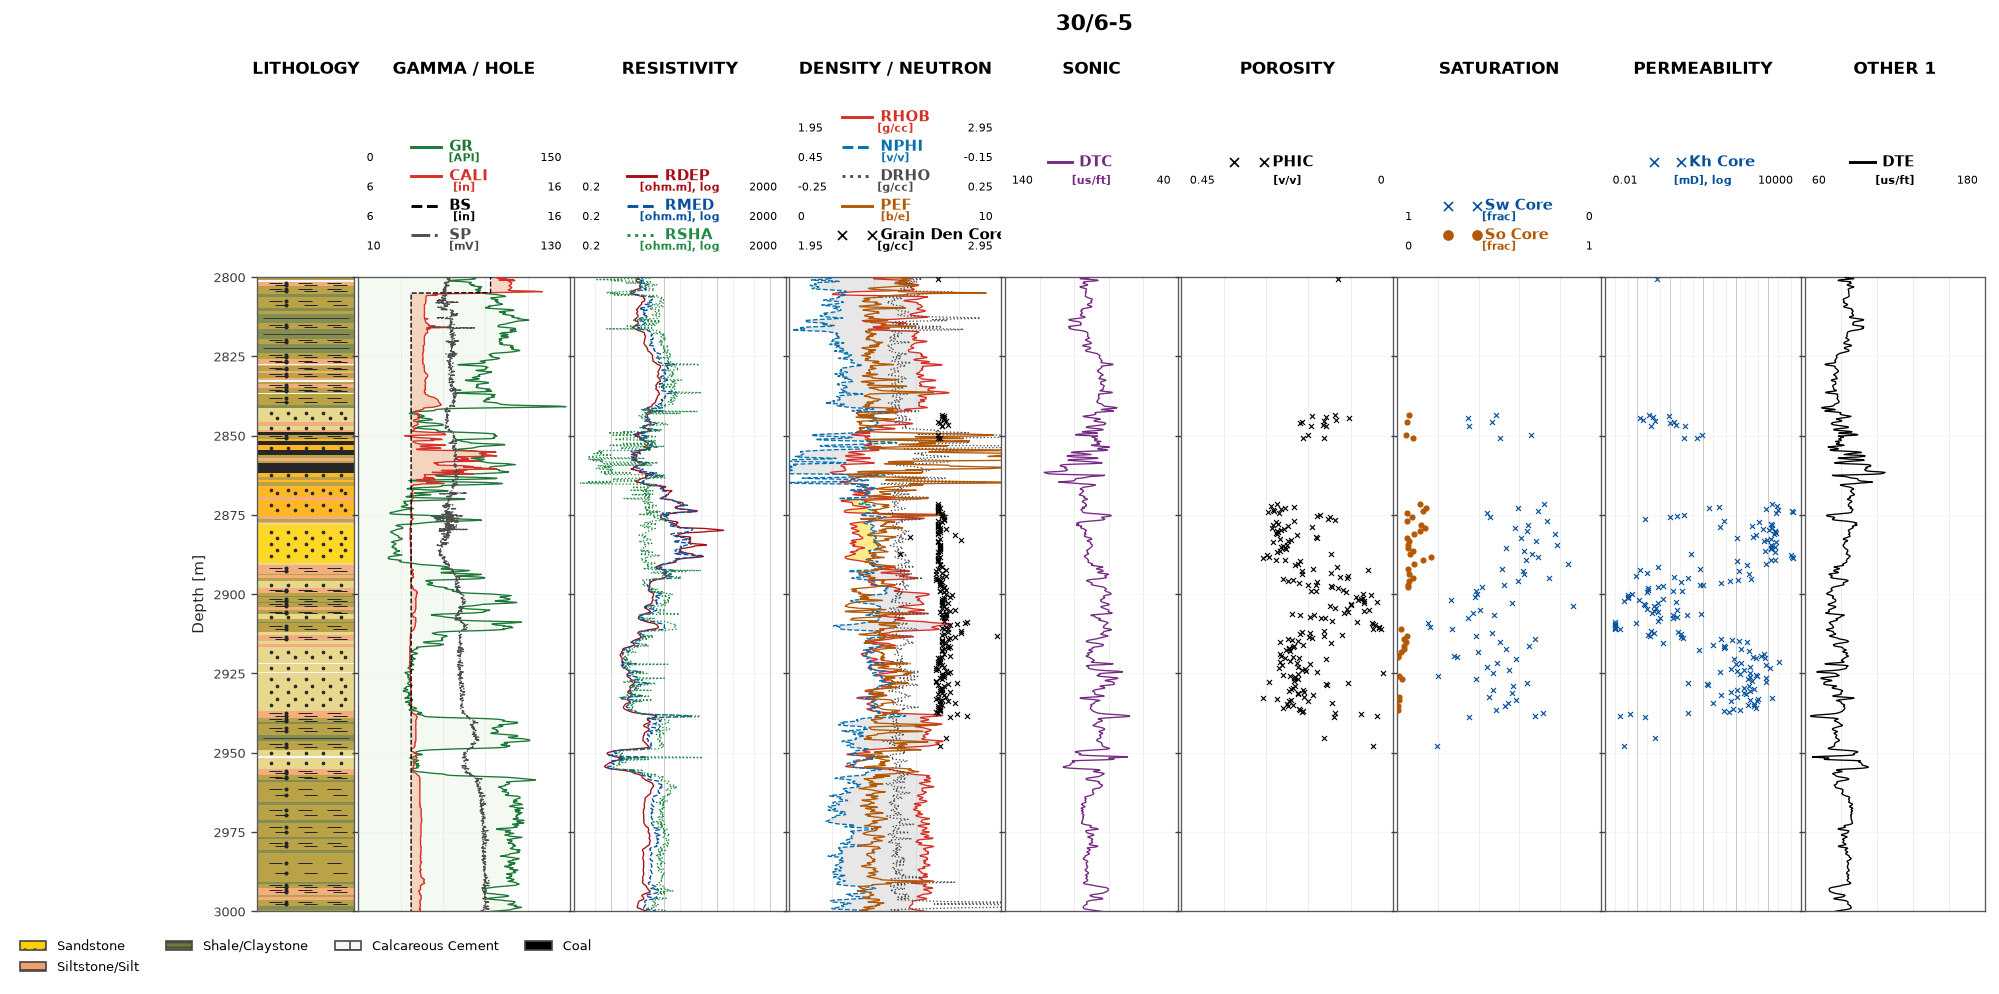

Available track names: ['DEPTH', 'LITHOLOGY', 'GAMMA / HOLE', 'RESISTIVITY', 'DENSITY / NEUTRON', 'SONIC', 'POROSITY', 'SATURATION', 'PERMEABILITY', 'OTHER 1']
Warnings: ["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.", "SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]


In [2]:
import petrophys as pp

raw_geo = pp.read(pp.sample("30_6-5"))
raw_viewer = pp.plot(raw_geo, depth_range=(2800, 3000), figsize=(15, 8))
raw_viewer.show()
raw_viewer.close()
print("Available track names:", [track.display_name for track in raw_viewer.template.tracks])
print("Warnings:", raw_viewer.warnings)

### Optional external geology and selected tracks

Attach formations and lithology with `pp.read` for use by both plotting and later interpretation. Passing `formation_tops` or `lithology_intervals` only to `pp.plot` affects that plot, not the well's interpretation context.

Below, track names deliberately select just porosity and saturation in the requested order. `curves=` selects curves instead: each goes to its usual track and a curve no track takes gets a generic track. A well whose mnemonics no alias table knows takes a curve-name mapping, `pp.read(path, curve_aliases="my_names.csv")` (columns `curve`, `standard`; a dict works too), which reading, interpretation and plotting all use. Invalid names raise an error; there is no silent guess. XML templates remain the advanced interface for styles and scales.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:750: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:750: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


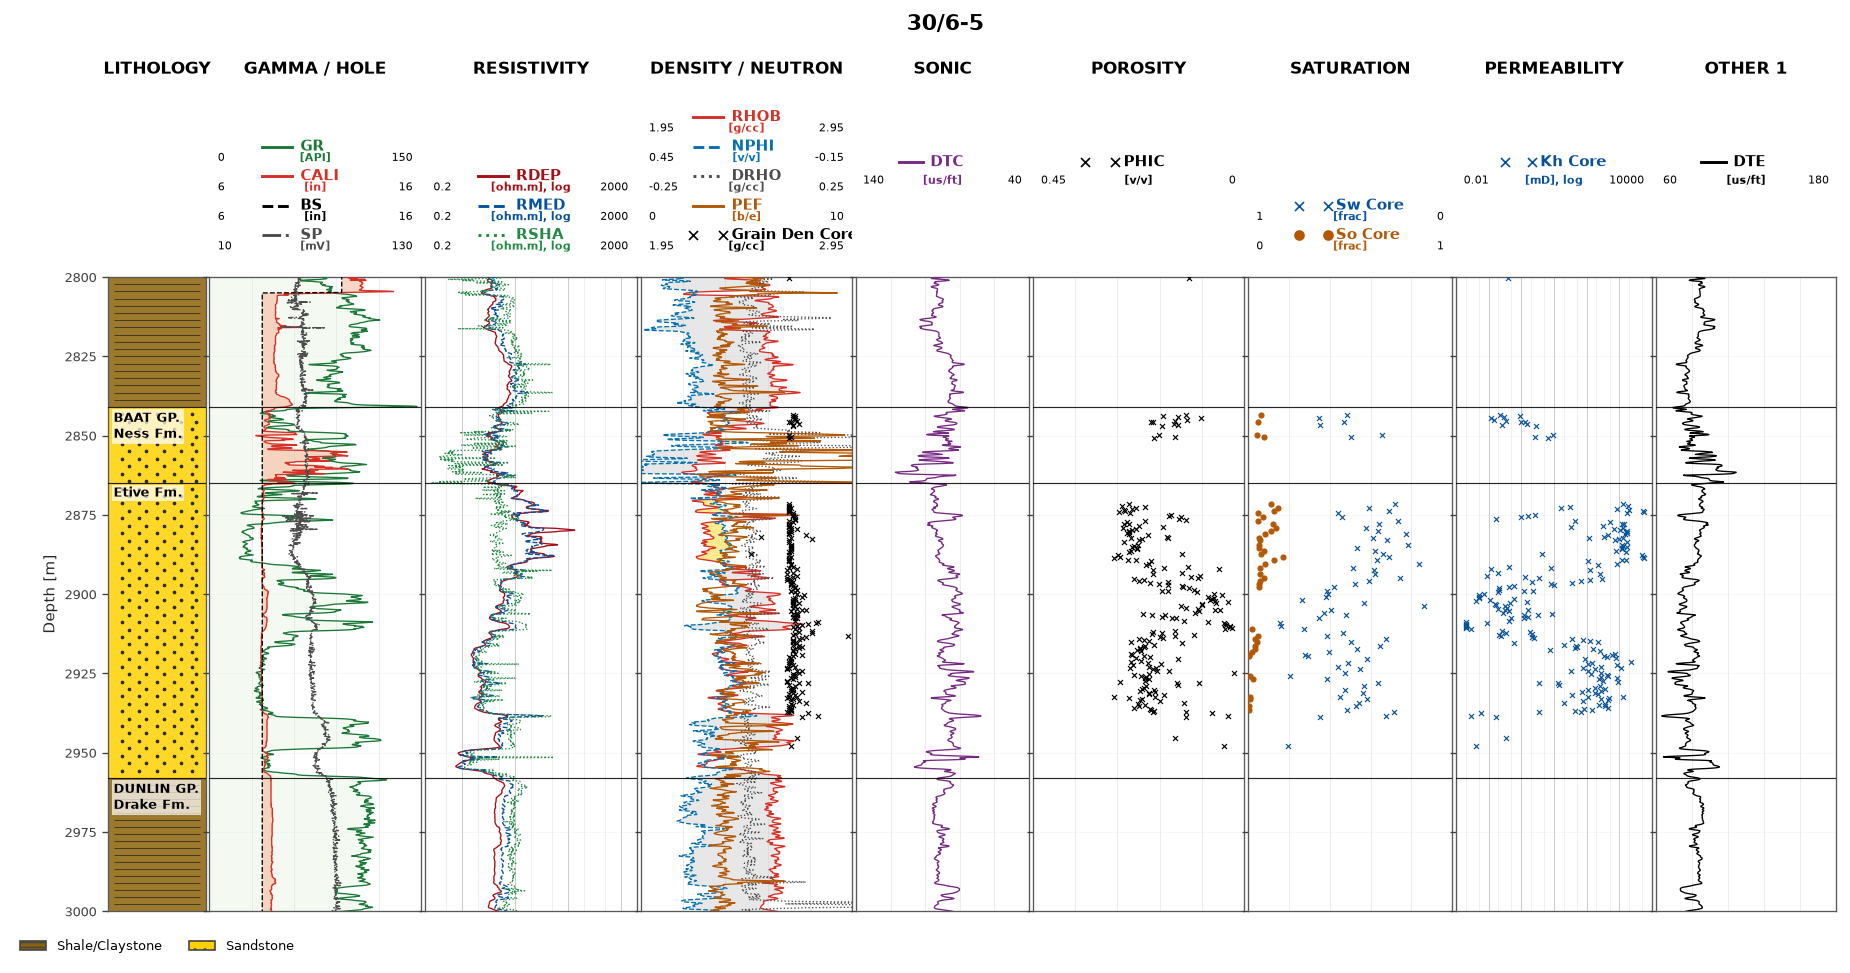

Selected lithology: external
Suppressed labels: []


[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:750: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:750: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


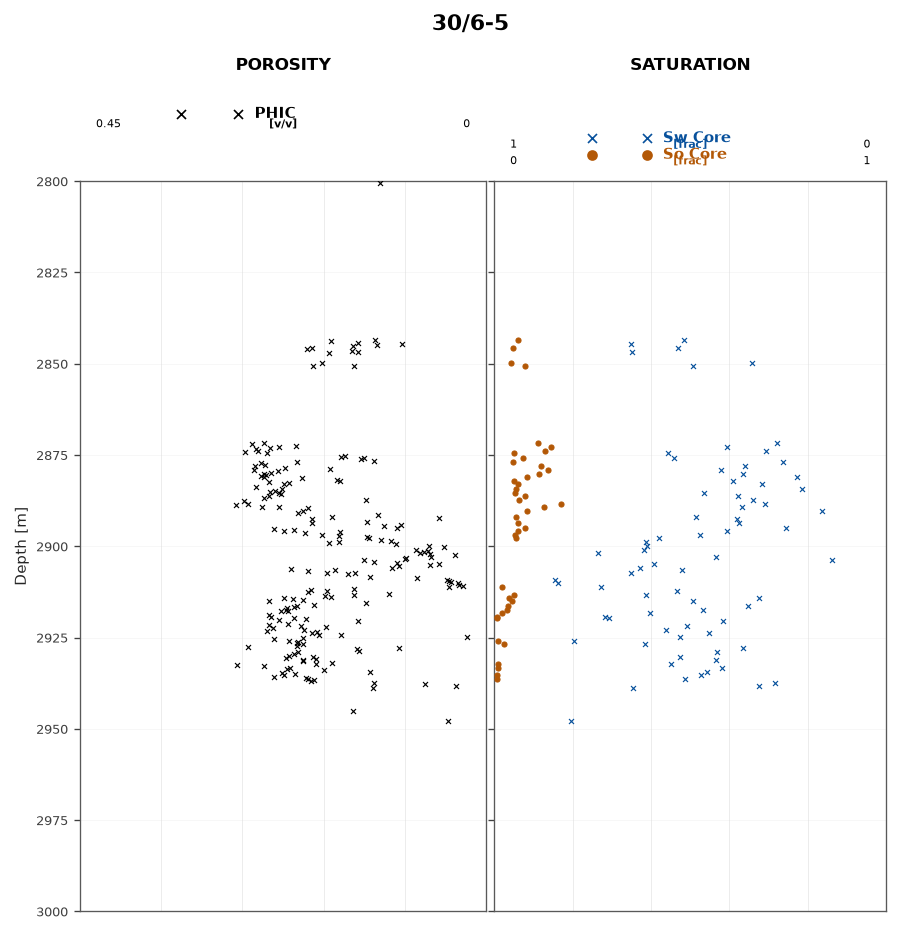

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:750: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:750: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


curves= -> [('DEPTH', []), ('GAMMA / HOLE', ['GR']), ('RESISTIVITY', ['RDEP']), ('DENSITY / NEUTRON', ['RHOB', 'NPHI'])]


In [3]:
context_geo = pp.read(
    pp.sample("30_6-5"),
    formations=pp.sample("formations_30_6-5"),
    lithology=pp.sample("lithology_30_6-5"),
)
context_viewer = pp.plot(context_geo, depth_range=(2800, 3000), figsize=(15, 8))
context_viewer.show()
context_viewer.close()
print("Selected lithology:", context_viewer.diagnostics["lithology_source"])
print("Suppressed labels:", context_viewer.diagnostics["suppressed_formation_labels"])

selected = pp.plot(raw_geo, tracks=["POROSITY", "SATURATION"],
                   depth_range=(2800, 3000), figsize=(7, 8))
selected.show()
selected.close()
assert [track.display_name for track in selected.template.tracks] == ["POROSITY", "SATURATION"]

few = pp.plot(raw_geo, curves=["GR", "RDEP", "RHOB", "NPHI"],
              depth_range=(2800, 3000), figsize=(7, 8))
print("curves= ->", [(t.display_name, [c.curve_name for c in t.curves]) for t in few.template.tracks])
few.close()

### Now interpret the teaching wells for the advanced figures

The remaining panels use calculated products. Each single-well run uses `pp.interpret`
and checks its result; batch processing is covered separately in lesson 18.

- **30/6-5**: we pass the study value Rw = 0.070 ohm.m *measured at 230 degF*
  (`rw=0.070, rw_meas_temp_f=230`), a teaching-study assumption. Without the
  temperature the library would take Rw at the median formation temperature, which
  changes saturation strongly.
- **HW-3** (a Costa carbonate well whose LAS covers only the Kharaib-2 reservoir
  interval): no Rw is passed. The LAS header carries Rw and the temperature it was
  measured at, and the workflow corrects that value to formation temperature.
  We pass `lithology_domain="carbonate"` because the domain defaults to
  `clastic`, which would interpret this carbonate with a sandstone matrix.
  Inside the carbonate domain the workflow picks the matrix itself: the warning
  printed below says it resolved **limestone** (by the route it names,
  `multi_mineral_solver`). The file has no core porosity, so the run keeps the
  file's own `PHIE_CC` / `PERM_CC` curves and, as the other warning says, uses
  them as they stand for SW, BVW, net pay and RQI; the check after the cell
  compares them with the run's own `PHIE` and `PERM`.

The cell prints each well's Rw decision from the trace, its skipped steps with
reasons, and its warnings. Neither the figures nor a successful run prove that every
scientific assumption is appropriate for another well.

In [4]:
geo_result = pp.interpret(raw_geo, rw=0.070, rw_meas_temp_f=230.0)  # Rw (ohm.m) at 230 degF
geo_result.raise_for_errors()
geo = geo_result.well
carb_result = pp.interpret(pp.read(pp.sample("HW-3")), lithology_domain="carbonate")  # Rw from the LAS header
carb_result.raise_for_errors()
carb = carb_result.well

for result in (geo_result, carb_result):
    steps = result.to_dataframe()
    print(f"== {result.well.name}: {result.status}, {result.well.n_samples} samples, "
          f"depth in {result.well.depth_unit}")
    print("   Rw:", steps.loc[steps["Step"] == "rw", "Decisions"].iloc[0])
    for step, reason in result.specific_steps_skipped.items():
        print(f"   skipped {step}: {reason}")
    for warning in result.warnings:
        print("   warning:", warning)

print("30/6-5 field:", geo.header.field)
print("30/6-5 interpreted curves present:",
      [c for c in ("VCL", "PHIE", "SW", "PERM", "NET_PAY") if geo.has_curve(c)])

# Reusable working intervals on 30/6-5:
GEO_FULL = (2600.0, 3200.0)     # broad reservoir section
GEO_LITH = (2784.0, 3176.0)     # PEF recorded here (offset high, see section 1) -> lithology crossplots
GEO_WATER = (3223.0, 3556.0)    # Statfjord water-bearing sand -> Pickett/Hingle

== 30/6-5: interpreted, 22176 samples, depth in m
   Rw: Rw corrected from 0.0700 ohm.m @ 230F along the temperature profile
   skipped spectral_gamma: Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_spectral_gamma directly
   skipped elemental_spectroscopy: Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_elemental_spectroscopy directly
   skipped hc_correction: apply_hc_correction=False (hydrocarbon correction is opt-in)
   skipped porosity_refinement: Not run by the interpretation workflow; porosity is computed once in the porosity step
== HW-3: interpreted, 431 samples, depth in ft
   Rw: Rw corrected from LAS metadata: 0.0682 ohm.m @ 68F along the temperature profile
   skipped bad_hole: Needs a density-correction (DRHO) curve, or a caliper (CALI) and a bit size (BS curve or a 3-36 in header bit size)
   skipped spectral_gamma: Not run by the interpretation workflow; use petrophys.interpretation

#### What the HW-3 defaults produce

Compare the workflow's own porosity and permeability (`PHIE`, `PERM`) with the
core-corrected curves delivered in the same LAS file, read from disk.

In [5]:
hw3_file = pp.read(pp.sample("HW-3"))
perm_run = np.asarray(carb.get("PERM").data, float)
finite_perm = np.isfinite(perm_run)
print("HW-3 median PHIE, this run      : %.3f" % np.nanmedian(carb.get("PHIE").data))
print("HW-3 median PHIE_CC, LAS file   : %.3f" % np.nanmedian(hw3_file.get("PHIE_CC").data))
print("HW-3 median PERM, this run      : %.0f mD" % np.nanmedian(perm_run))
print("HW-3 median PERM_CC, LAS file   : %.1f mD" % np.nanmedian(hw3_file.get("PERM_CC").data))
print("HW-3 PERM samples at the 10,000 mD clip: %.0f%%"
      % (100 * np.mean(perm_run[finite_perm] >= 10000.0)))

HW-3 median PHIE, this run      : 0.216
HW-3 median PHIE_CC, LAS file   : 0.290
HW-3 median PERM, this run      : 6065 mD
HW-3 median PERM_CC, LAS file   : 7.3 mD
HW-3 PERM samples at the 10,000 mD clip: 26%


The run's `PHIE` reads below the file's core-corrected porosity (median 0.216
against 0.290), and its permeability is far from the file's `PERM_CC`. The
default carbonate route uses a Coates-type transform with an irreducible
saturation taken from the low end of the computed Sw; at this well's porosity
its median is about three orders of magnitude above the delivered `PERM_CC`,
and about a quarter of the samples sit at the 10,000 mD clip. That permeability is **uncalibrated** and should
not be read as a property of the rock. The figures below still use it, to show
the plot types; where it appears (the HW-3 permeability track and the Buckles
colour scale), read it as uncalibrated output. For a study, use the file's
`PERM_CC` (the workflow carries it unchanged and uses it for RQI) or calibrate
the permeability transform to core.

## 1. Template log viewer

`create_log_viewer` builds a multi-track figure from a PetroPy-style **XML template**.
You can pass a named built-in template via `template_defaults=...` or let it choose one
automatically with `"auto"`. The available names are the keys of
`DEFAULT_LOG_VIEWER_TEMPLATES` (several are aliases pointing at the same XML).

The factory renders **eagerly**: pass `depth_range=` (and any styling) to
`create_log_viewer` itself, and the returned `LogViewer` already holds the finished,
windowed figure as `viewer.fig` / `viewer.axes`. Do **not** call `.create()` on it
again - that re-renders from scratch and, called bare, falls back to the full well.
Use `.save(path)` to export and `.close()` to free memory in loops; unrecognised or
dropped curves are recorded in `viewer.warnings`.

`pp.plot(well, ...)`, `result.plot(...)`, and `create_log_viewer(well, ...)` share this LogViewer return contract. Specialized crossplots retain their documented return types; they are not all LogViewer objects.

geolink_full template -> 9 tracks
viewer.warnings: 10
  - Curve 'RXO' not available for log viewer template
  - Curve 'NPHI_HC' not available for log viewer template
  - Curve 'PHIT_GAS_CORR' not available for log viewer template
  - Curve 'SW_ARCHIE' not available for log viewer template
  - Curve 'SW_INDONESIAN' not available for log viewer template
  - Curve 'SW_SIMANDOUX' not available for log viewer template
  - SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  - Curve 'PERM_TIMUR' not available for log viewer template
  - Curve 'PERM_COATES' not available for log viewer template
  - Curve 'PERM_MORRIS_BIGGS_MODIFIED' not available for log viewer template

Clean Etive sand (336 samples): median PEF 4.40 b/e (quartz 1.81, calcite 5.08)
  solver volumes there: median VQUAR 0.14, VCALC 0.54


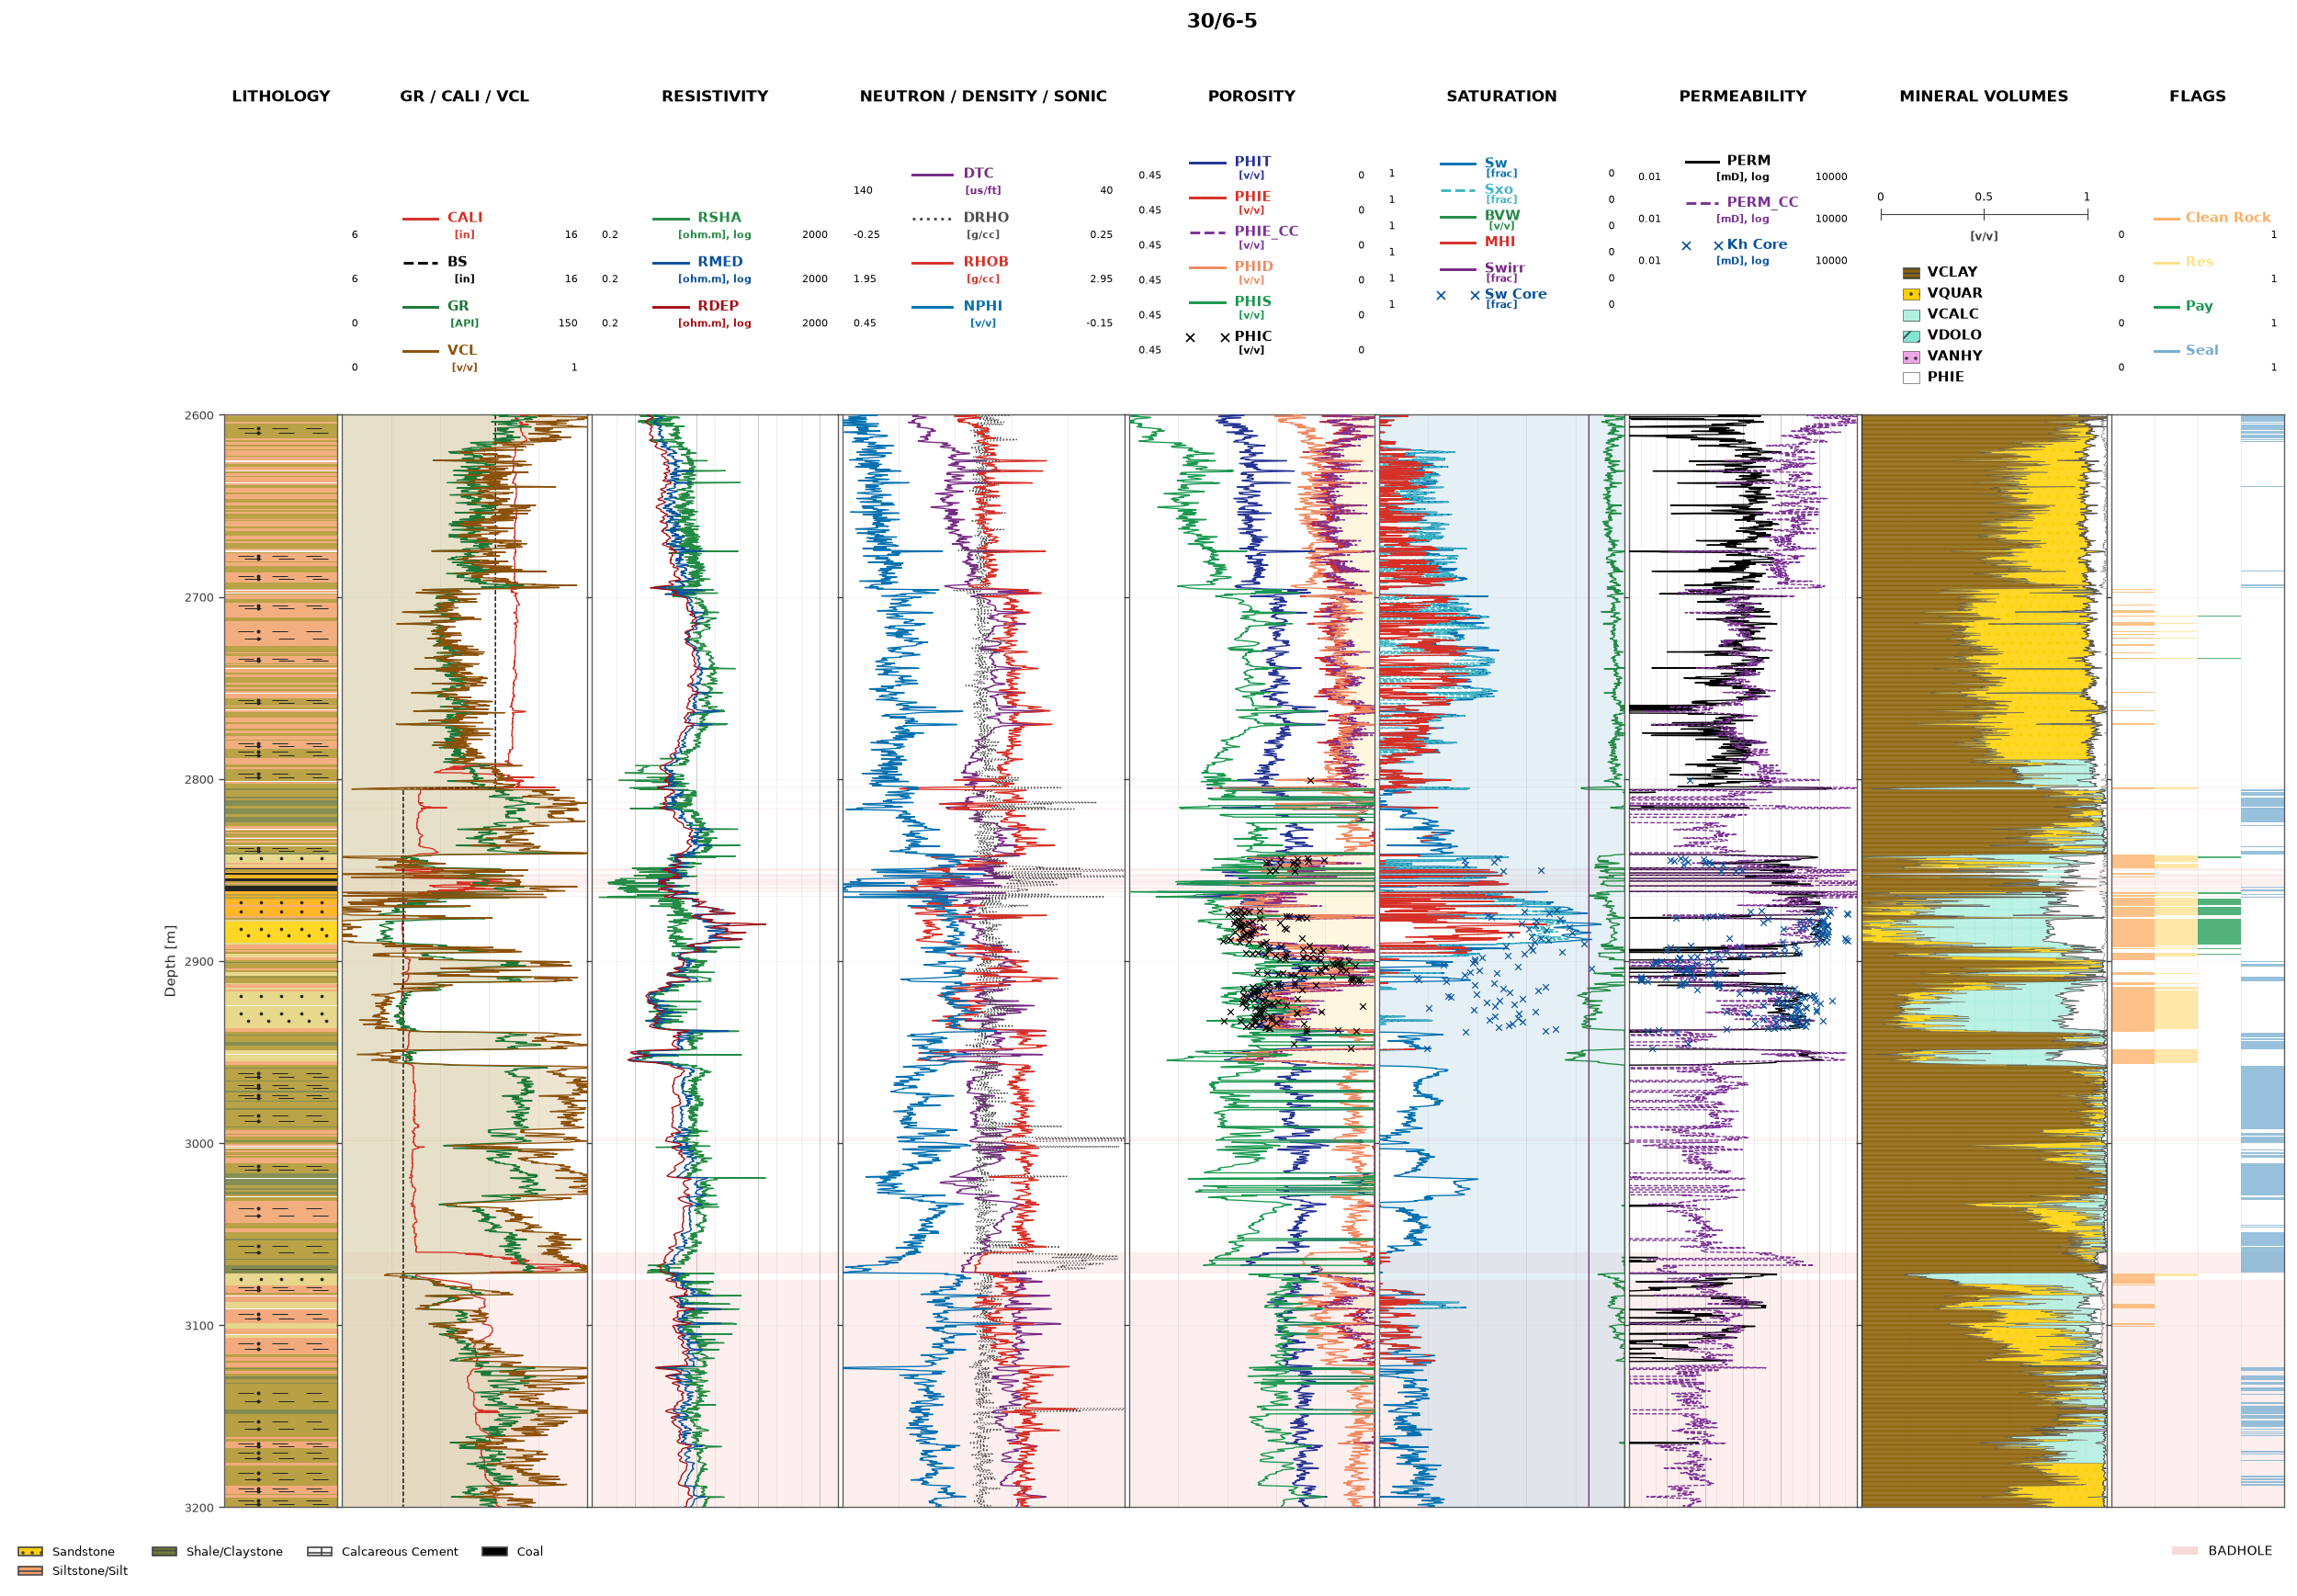

In [6]:
viewer = create_log_viewer(geo, template_defaults="geolink_full", depth_range=GEO_FULL)
print("geolink_full template ->", len(viewer.axes), "tracks")
print("viewer.warnings:", len(viewer.warnings))
for w in viewer.warnings:
    print("  -", w)

# PEF check in clean, gauge-hole Etive sand (GR < 50 API), where the rock is quartz sand.
d_geo = np.asarray(geo.depth, float)
clean_etive = (d_geo >= 2865.0) & (d_geo <= 2958.0) & (np.asarray(geo.get("GR").data, float) < 50.0)
print()
print("Clean Etive sand (%d samples): median PEF %.2f b/e (quartz 1.81, calcite 5.08)"
      % (clean_etive.sum(), np.nanmedian(geo.get("PEF").data[clean_etive])))
print("  solver volumes there: median VQUAR %.2f, VCALC %.2f"
      % (np.nanmedian(geo.get("VQUAR").data[clean_etive]),
         np.nanmedian(geo.get("VCALC").data[clean_etive])))

**Read the MINERAL VOLUMES track with care.** It shows the Brent sandstones as
mostly calcite. The PEF explains why: clean Etive sand reads about 4.4 b/e
(printed above), close to calcite and far from quartz, and the overlying Heather
shale reads nearly as high (about 4.1 b/e). The whole PEF run is shifted upward, as it is when the
mud is weighted with barite, while the GeoLink labels and core grain densities of
2.66-2.67 g/cm3 describe quartz sandstone with only thin calcite-cemented
streaks. A multi-mineral solver that trusts this PEF turns quartz into calcite.
Before using PEF for lithology, check it against a known clean sand; here it
should be excluded or corrected.

### The adaptive `auto` template

`template_defaults="auto"` inspects the curves actually present and assembles tracks on
the fly (gamma/hole, resistivity, density-neutron, porosity, saturation, permeability,
flags, ...), skipping any family the well lacks. This is the safe default for an unknown
LAS. Logged curves no named track takes go to generic `OTHER` tracks; interpretation
intermediates (`VCL_GR`, `PHI_SEC`, flags drawn as shading) and exact copies of a drawn
curve stay out. The computed temperature profile and Rw/Rmf tracks are optional: they are
listed in `viewer.diagnostics["optional_tracks"]` and drawn when `tracks=` names them. `create_adaptive_log_viewer_template` exposes that template object directly so you
can see what it decided.

adaptive template tracks:
  DEPTH              []
  LITHOLOGY          ['LITHOLOGY_GEOLINK']
  GAMMA / HOLE       ['GR', 'VCL', 'CALI', 'BS', 'SP']
  RESISTIVITY        ['RDEP', 'RMED', 'RSHA']
  DENSITY / NEUTRON  ['RHOB', 'NPHI', 'DRHO', 'PEF', 'GDEN']
  SONIC              ['DTC']
  POROSITY           ['PHIT', 'PHIE', 'PHIE_CC', 'PHID', 'PHIS', 'PHIN', 'PHIC', 'BVW']
  SATURATION         ['SW', 'SXO', 'MHI', 'SWIRR_APP', 'SWC', 'SOC']
  PERMEABILITY       ['PERM', 'PERM_CC', 'KH_CORE']
  ROCK QUALITY       ['RQI', 'FZI']
  MINERAL VOLUMES    ['VCLAY', 'VQUAR', 'VCALC', 'VDOLO', 'VANHY']
  TEMPERATURE        ['TEMP']
  RW / RMF           ['RW', 'RMF']
  FLAGS              ['NET_ROCK', 'NET_RES', 'NET_PAY', 'SEALFLAG']


optional tracks left out: ['TEMPERATURE', 'RW / RMF']


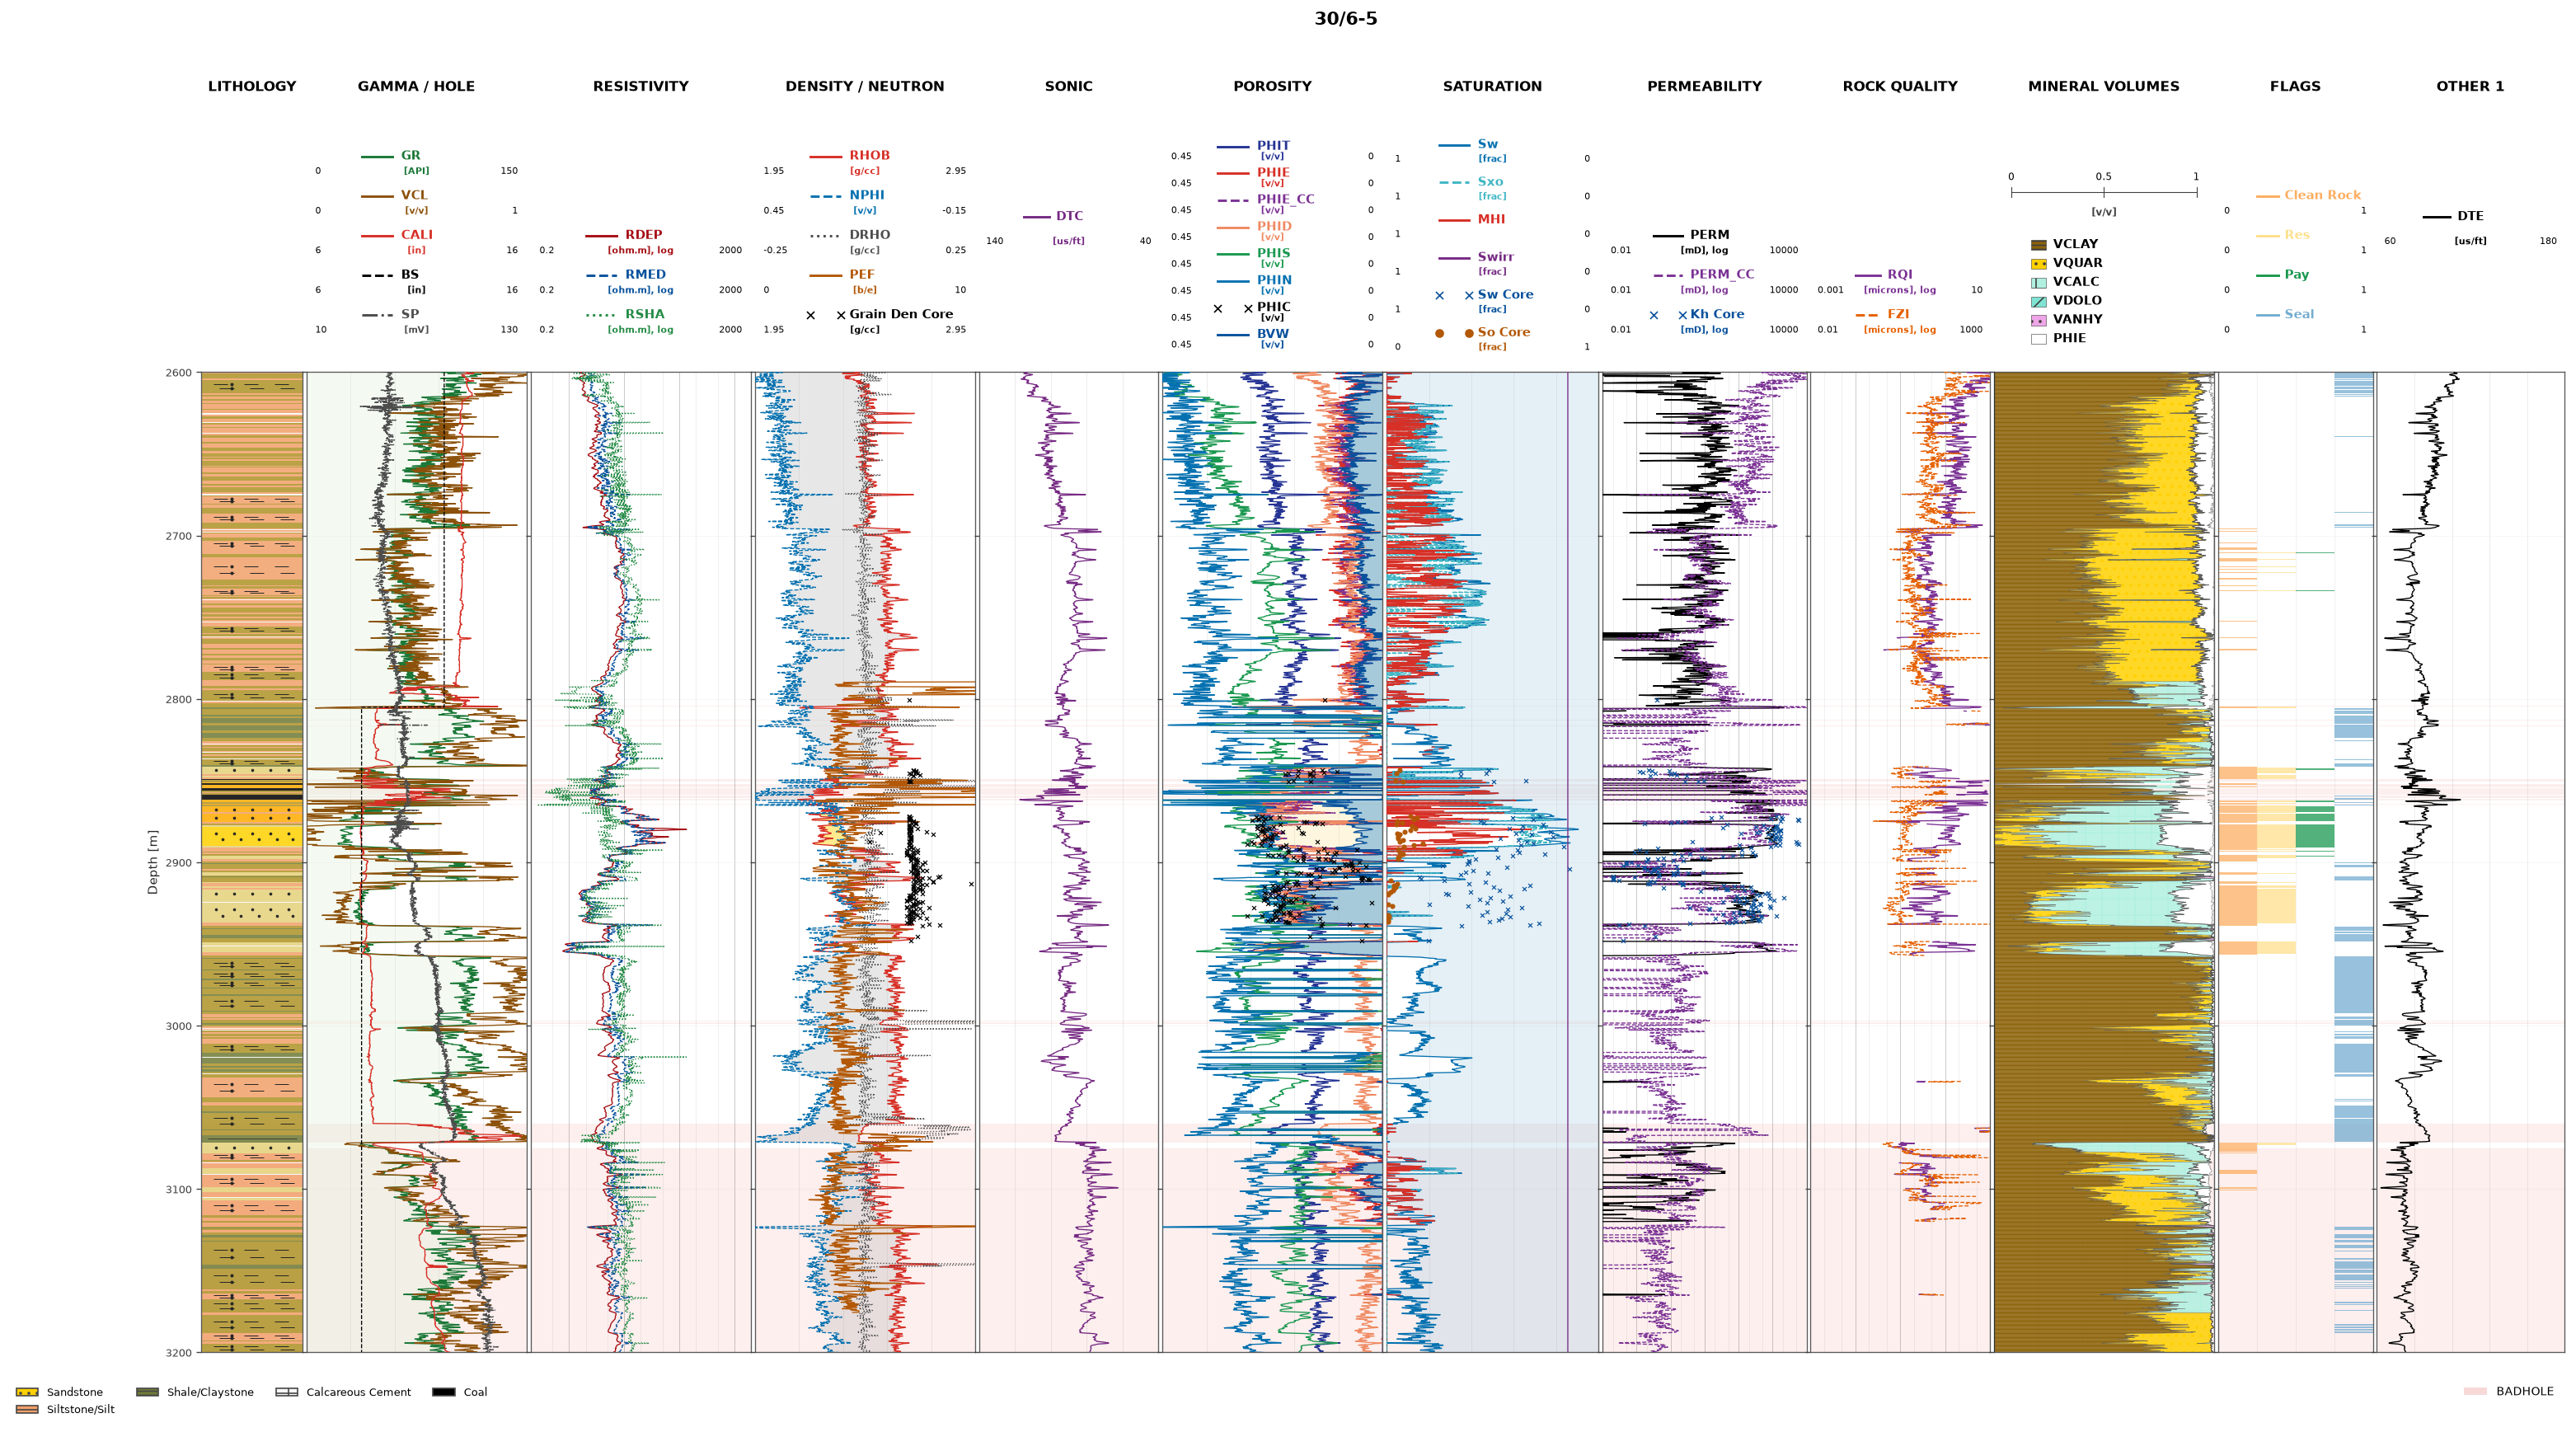

In [7]:
tmpl = create_adaptive_log_viewer_template(geo)
print("adaptive template tracks:")
for t in tmpl.tracks:
    curves = [c.curve_name for c in t.curves]
    print("  %-18s %s" % (t.display_name, curves))

viewer = create_log_viewer(geo, template_defaults="auto", depth_range=GEO_FULL)
print("optional tracks left out:", viewer.diagnostics["optional_tracks"])

The same `auto` template adapts to the carbonate well, which has fewer curves and no
vendor lithology log - note the different track set it produces. Its `PERM` curve
sits mostly near the right-hand edge: the default permeability runs to thousands
of mD and about a quarter of it is clipped at 10,000 mD, far above the dashed
`PERM_CC` from the file (see the HW-3 check above).

HW-3 auto -> 11 tracks


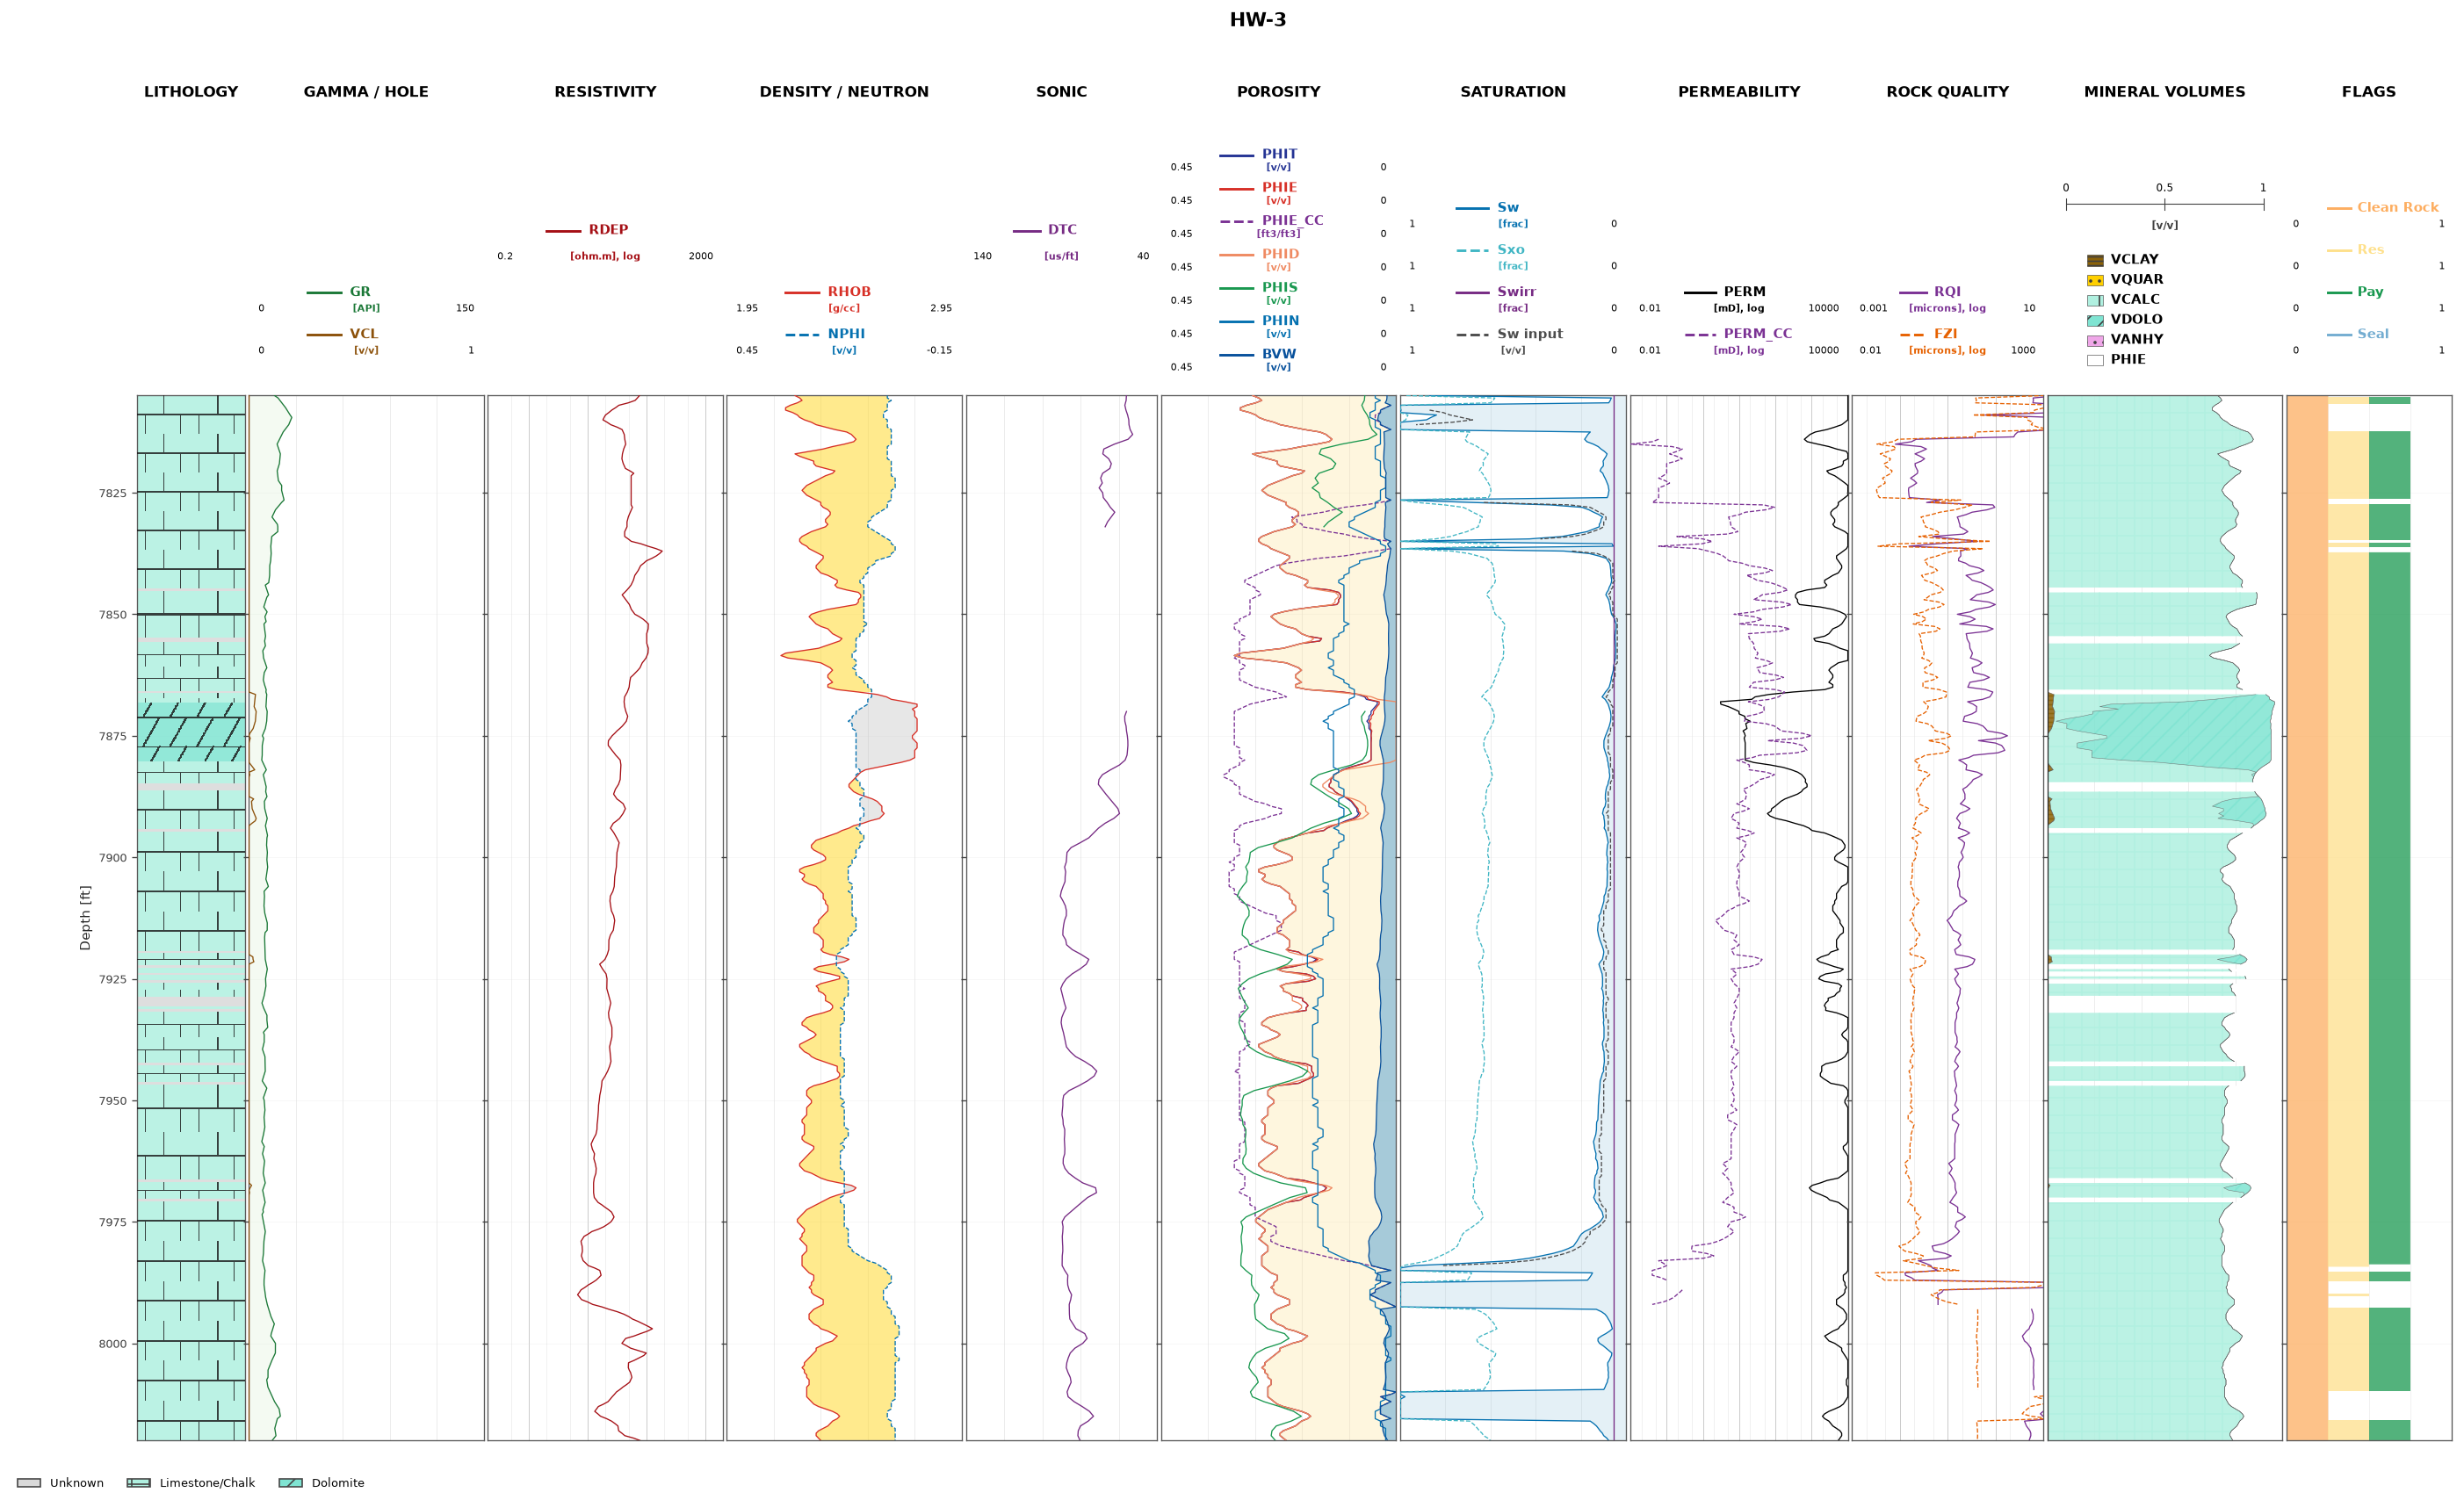

In [8]:
viewer = create_log_viewer(carb, template_defaults="auto")
print("HW-3 auto ->", len(viewer.axes), "tracks")

## 2. Triple combo

`create_triple_combo` is the classic quick-look, and "triple" means exactly
three measurement families in three tracks:

1. **Correlation** - GR (shaded), SP, and caliper against bit size. SP lives
   here, with GR, per industry convention.
2. **Resistivity** - deep / medium / shallow on a log scale.
3. **Porosity** - neutron and density on compatible scales (NPHI 0.45 to -0.15
   v/v against RHOB 1.95 to 2.95 g/cc), with the DRHO QC curve dotted.

It is the fastest way to eyeball reservoir vs seal and hydrocarbon crossover.
Sonic is deliberately not part of the display - adding it makes a quad combo,
which you can build with a custom template. One call, sensible defaults.

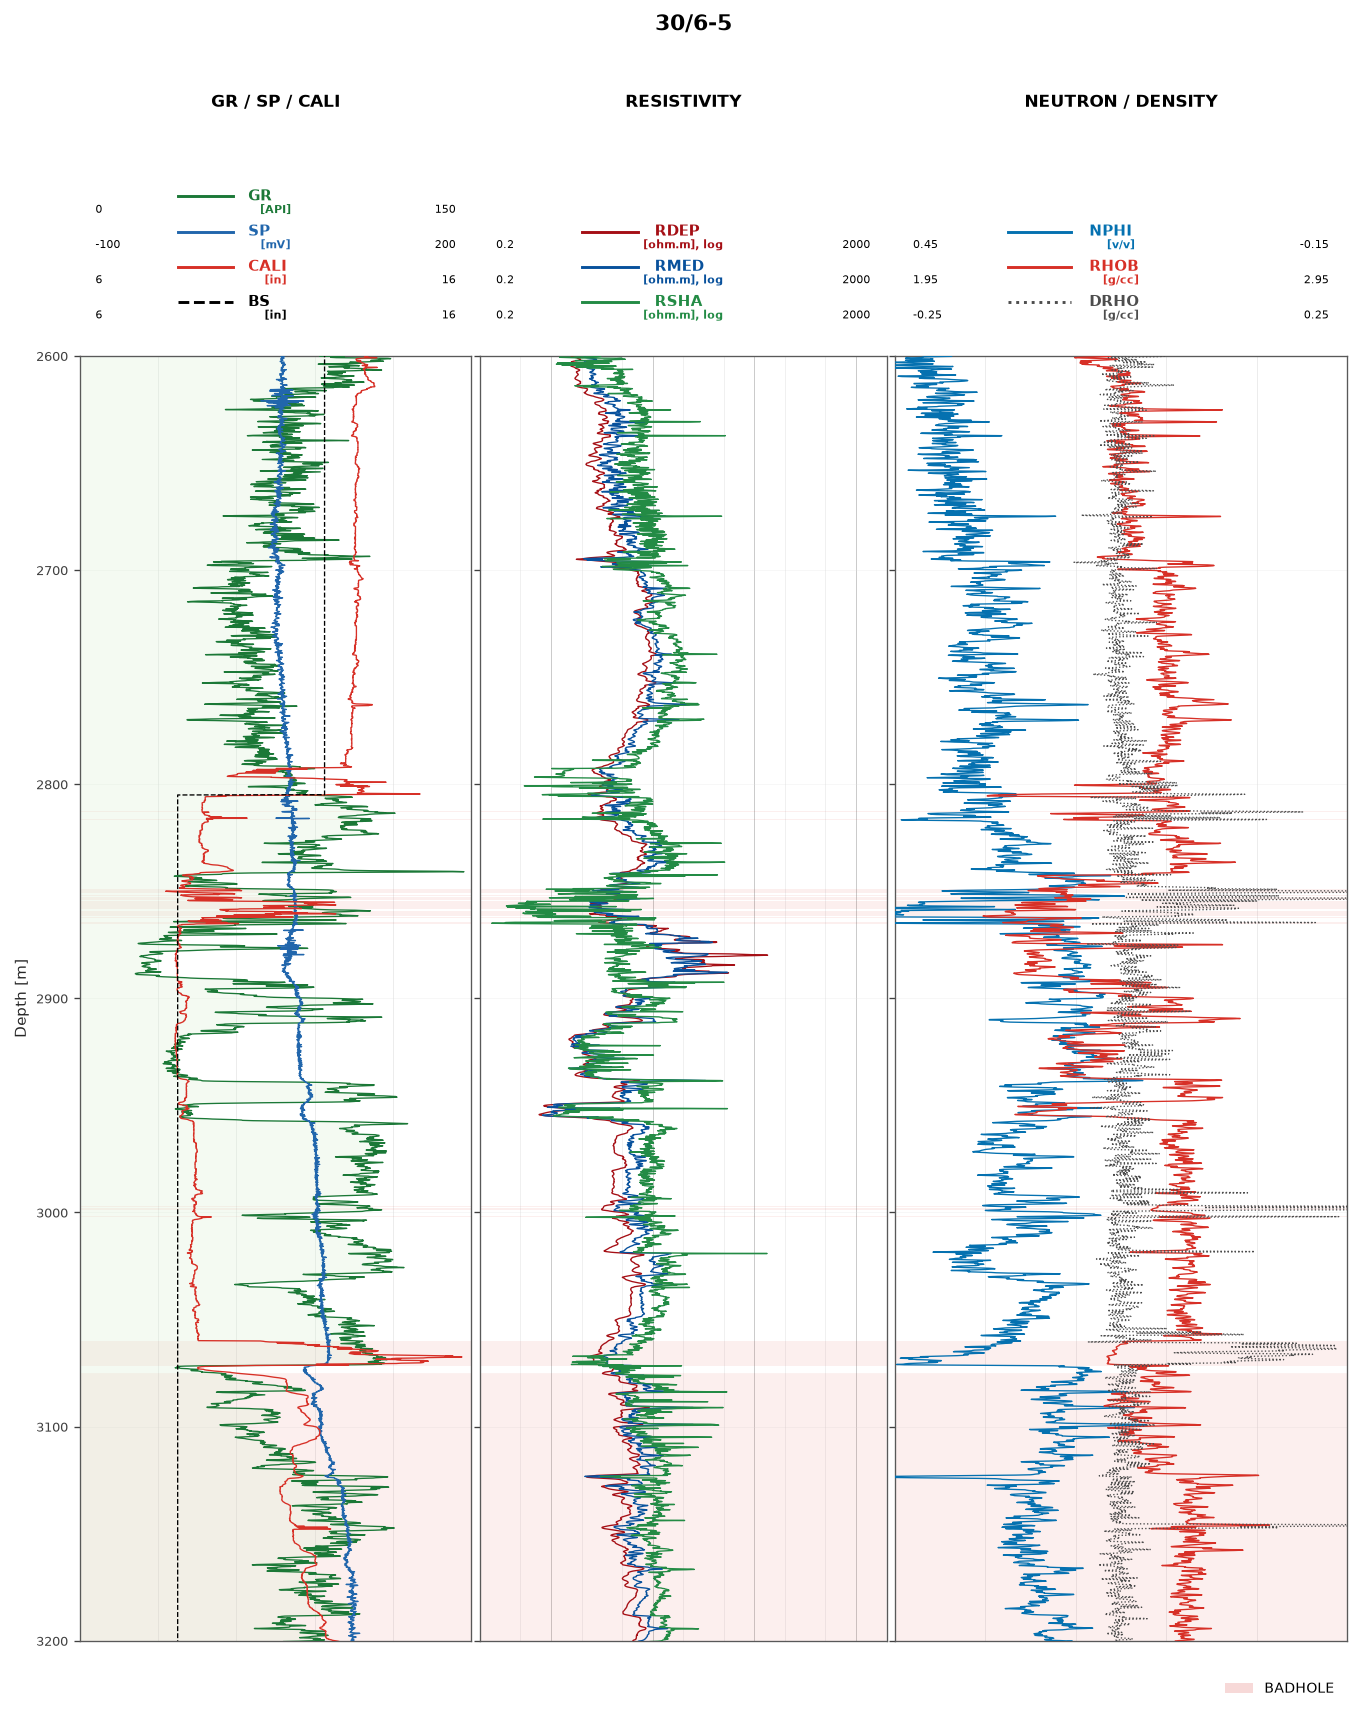

In [9]:
create_triple_combo(geo, depth_range=GEO_FULL)
plt.show()

## 3. The crossplot family

Crossplots move from depth-vs-value tracks to **value-vs-value** scatter, which is where
lithology, porosity model, and saturation logic become visible.

### 3a. Neutron-density crossplot

`create_nd_crossplot` plots NPHI against RHOB with lithology lines; points are coloured
by a third curve (default `GR`). Sandstone, limestone, and dolomite trends separate here,
and gas pulls points toward low apparent density / low neutron. We restrict to the interval
where the full lithology suite (including PEF) was recorded on 30/6-5; the N-D
crossplot itself uses only NPHI and RHOB, so the PEF offset noted in section 1
does not affect it.

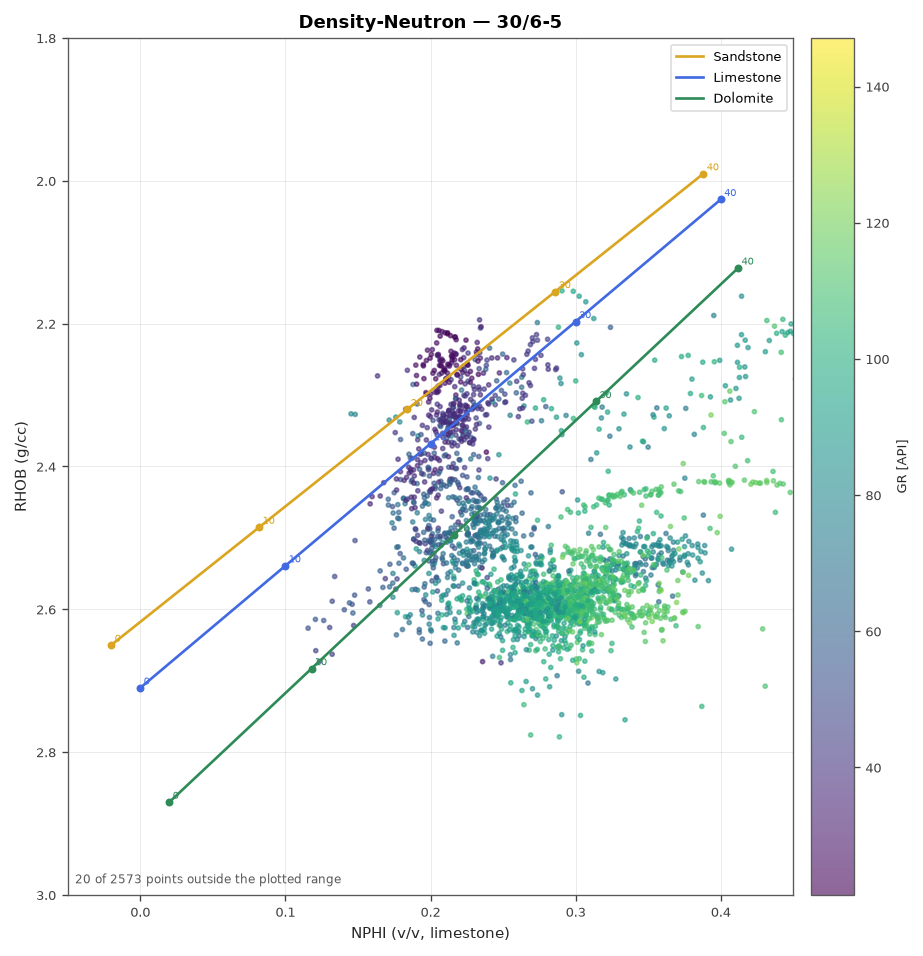

In [10]:
create_nd_crossplot(geo, color_curve="GR", depth_range=GEO_LITH)
plt.show()

### 3b. Pickett plot

`create_pickett_plot` plots `log(RT)` vs `log(PHIE)`. In a clean, water-bearing zone the
100%-water points scatter about a straight line whose slope is `-m` (its magnitude is the
cementation exponent) and whose intercept fixes `Rw`. Hydrocarbon points sit **above**
the water line. We run it on the Statfjord water sand (a hydrocarbon interval would give
too few water points).

The parameters are not free knobs: we use the operator's own evaluation constants
(a=0.80, m=n=2, Rw=0.070 ohm.m measured at 230 degF, from the Statoil completion report
validated in lesson 09). `create_pickett_plot` draws its Sw lines with the single Rw you
pass; it does not correct Rw for temperature.

Rather than assume the constants fit, the cell below tests them. It computes the median
**apparent water resistivity** of the clean points in this window,
Rwa = Rt x PHIE^m / a, and prints how far it lies from 0.070 in percent. On a truly wet
interval Rwa equals Rw. Because Archie saturation scales as (Rw/Rwa)^(1/n), a mismatch
moves the water points by only about half as many percent in Sw (n = 2); the cell
prints the Sw at which the median water point plots. For comparison it also prints the
workflow's own temperature-corrected Rw and its computed SW over the same window: the
Statfjord lies deeper, and therefore hotter, than 230 degF, so its Arps-corrected Rw is
lower than 0.070. (Plotting the same window with a too-low guess like Rw=0.030 strands
the entire water sand at an apparent Sw of 60-80%: the classic mis-parameterised
Pickett from lesson 07.)

findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Failed to find font weight bold for DejaVu Sans, now using 400.


findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.


... (14 outputs left out)

findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


findfont: Failed to find font weight bold for DejaVu Sans, now using 400.


findfont: Font family ['DejaVu Sans Mono'] not found. Falling back to DejaVu Sans.


median apparent Rw (Rt x PHIE^m / a), 802 clean points: 0.070 ohm.m
study Rw (at 230 degF)                              : 0.070 ohm.m
difference +1% -> the median water point plots at Sw = 1.00
workflow Rw corrected to this window's temperature  : 0.065 ohm.m (median)
workflow SW in this window                          : 1.00 (median)


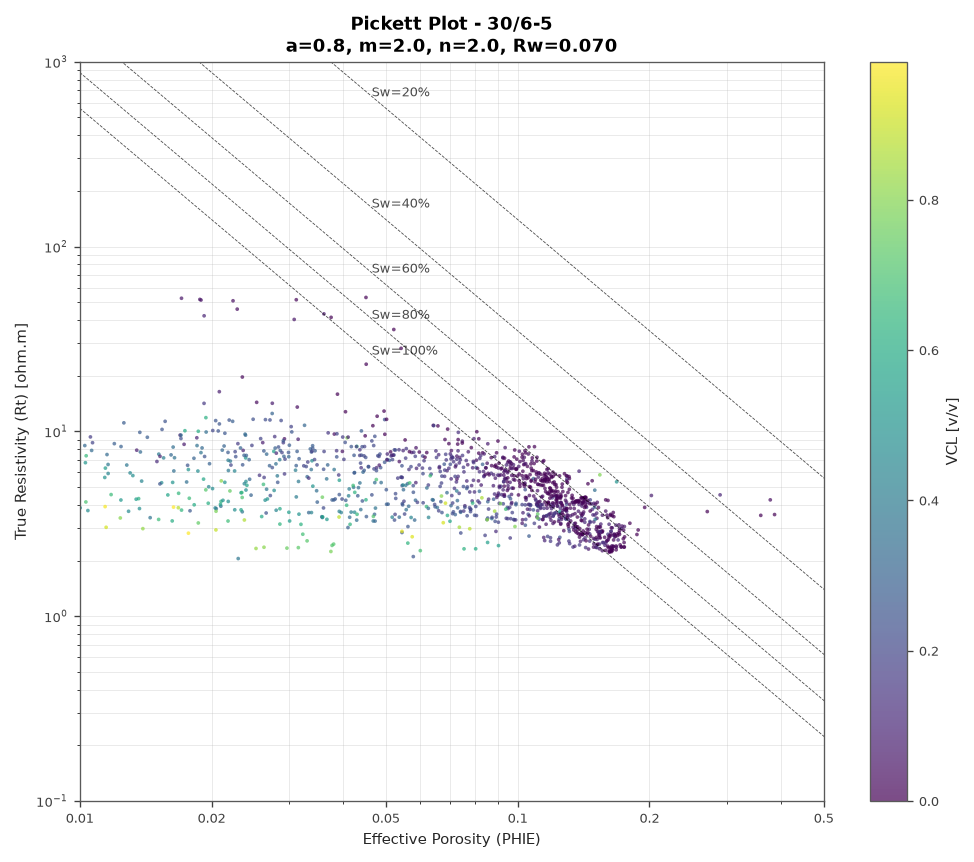

In [11]:
# Self-check: apparent Rw of the clean water-sand points at the operator's a, m, n.
A, M, N = 0.80, 2.0, 2.0
RW_STUDY = 0.070                     # ohm.m, measured at 230 degF
d = np.asarray(geo.depth, float)
mwin = (d >= GEO_WATER[0]) & (d <= GEO_WATER[1])
phi_w = np.asarray(geo.get("PHIE").data, float)[mwin]
rt_w = np.asarray(geo.get("RDEP").data, float)[mwin]
vcl_w = np.asarray(geo.get("VCL").data, float)[mwin]
clean = np.isfinite(phi_w) & np.isfinite(rt_w) & np.isfinite(vcl_w) & (vcl_w < 0.3) & (phi_w > 0.05) & (rt_w > 0)
rw_app = float(np.nanmedian(rt_w[clean] * phi_w[clean] ** M)) / A
diff_pct = 100.0 * (rw_app - RW_STUDY) / RW_STUDY
sw_median_point = (RW_STUDY / rw_app) ** (1.0 / N)
print(f"median apparent Rw (Rt x PHIE^m / a), {clean.sum()} clean points: {rw_app:.3f} ohm.m")
print(f"study Rw (at 230 degF)                              : {RW_STUDY:.3f} ohm.m")
print(f"difference {diff_pct:+.0f}% -> the median water point plots at Sw = {sw_median_point:.2f}")
print(f"workflow Rw corrected to this window's temperature  : "
      f"{np.nanmedian(geo.get('RW').data[mwin]):.3f} ohm.m (median)")
print(f"workflow SW in this window                          : "
      f"{np.nanmedian(geo.get('SW').data[mwin]):.2f} (median)")

create_pickett_plot(
    geo, rw=RW_STUDY, phie_curve="PHIE", rt_curve="RDEP",
    color_curve="VCL", depth_range=GEO_WATER, a=A, m=M, n=N,
)
plt.show()

### 3c. Hingle plot

`create_hingle_plot` is the Pickett plot's linear-grid cousin: it linearises the Archie
relation so the water line and `Rw` can be read on ordinary axes. Same water interval, same
operator parameters (a=0.80, m=n=2, Rw=0.070 ohm.m at 230 degF), different projection -
useful when you want to fit the water line by eye. On this projection wetter rock plots
higher (more conductive at a given porosity). The clean, low-`VCL` points should hug the
Sw=100% line, sitting slightly below it if the apparent Rw computed above exceeds 0.070;
shaly, high-`VCL` points can plot above it at low porosity, because clay conductivity is
not part of the Archie relation.

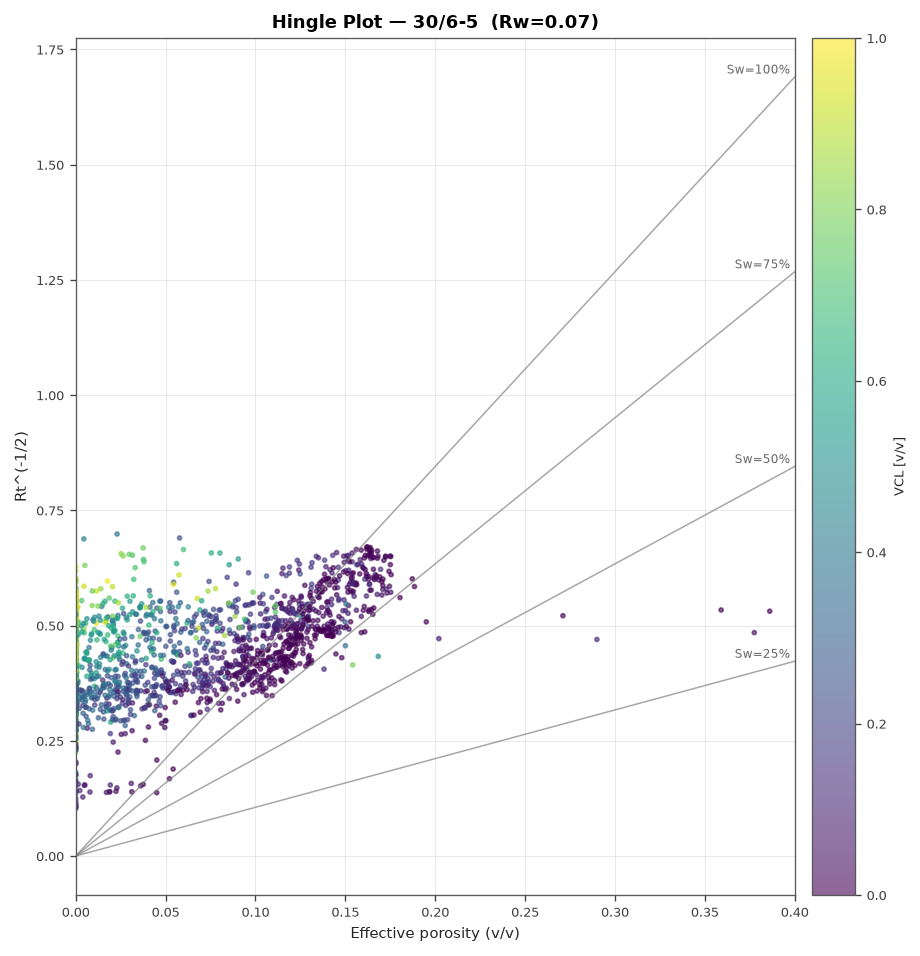

In [12]:
fig = create_hingle_plot(
    geo, rw=RW_STUDY, m=M, n=N, phie_curve="PHIE", rt_curve="RDEP",
    color_curve="VCL", a=A, depth_range=GEO_WATER,
)
plt.show()

### 3d. M-N and MID lithology crossplots

`create_mn_plot` and `create_mid_plot` combine density, neutron, and sonic to identify
matrix mineralogy and flag secondary porosity / gas independent of a single crossplot.
Both need a sonic curve, which 30/6-5 has (`DTC`). Coloured by `GR`.

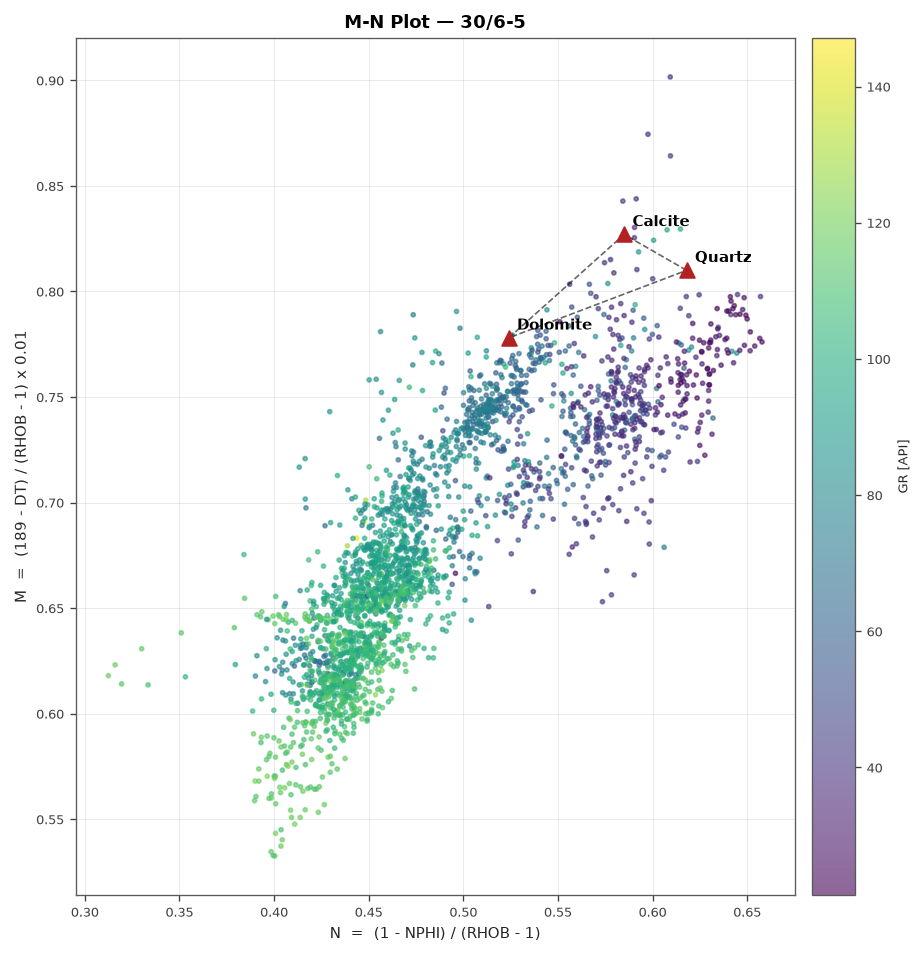

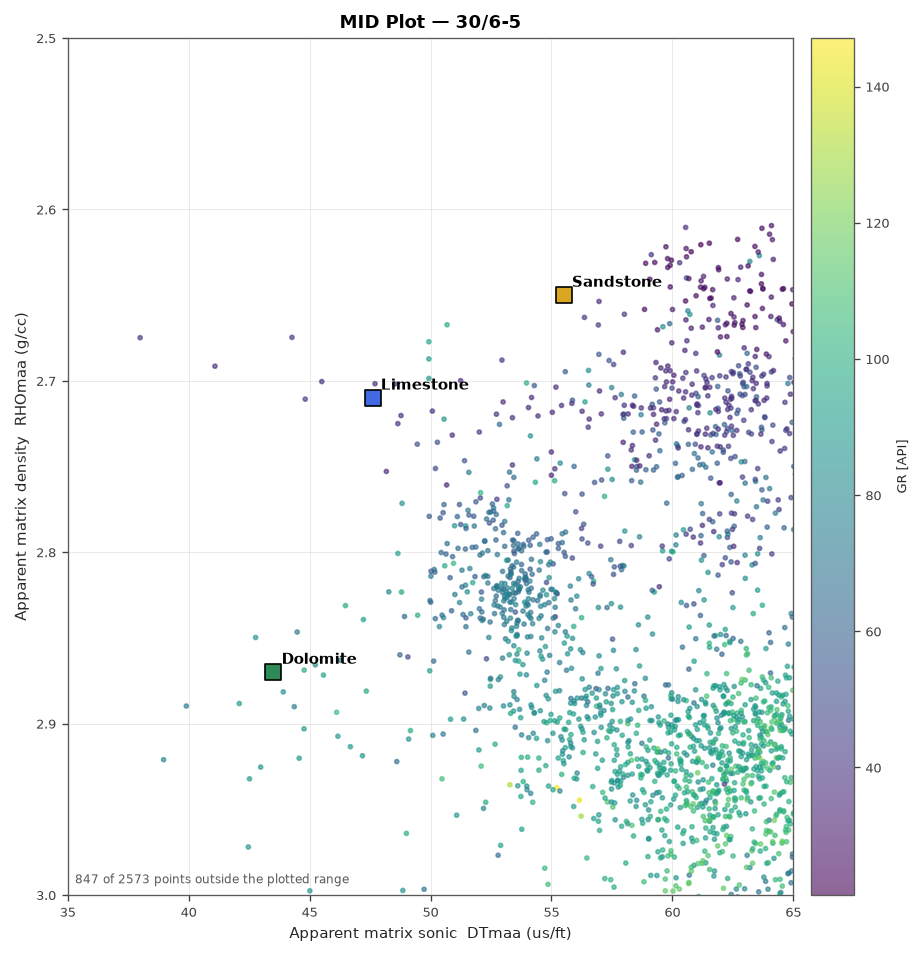

In [13]:
create_mn_plot(geo, color_curve="GR", depth_range=GEO_LITH)
plt.show()

create_mid_plot(geo, color_curve="GR", depth_range=GEO_LITH)
plt.show()

### 3e. Buckles plot

`create_buckles_plot` shows `PHIE` vs `SW`; points on a common `PHIE * SW = const`
hyperbola indicate a zone at **irreducible water** (constant bulk-volume water), which
predicts water-free production. Coloured by permeability. This is a carbonate reservoir
question, so we run it on HW-3 (its LAS covers the Kharaib-2 reservoir interval).
The colour scale carries little information about the rock here: the default
HW-3 `PERM` is uncalibrated (median in the thousands of mD, about a quarter at
the 10,000 mD clip; see the HW-3 check), so the colour mostly follows porosity
and most points take the upper colours. Read the plot for its PHIE-SW pattern.

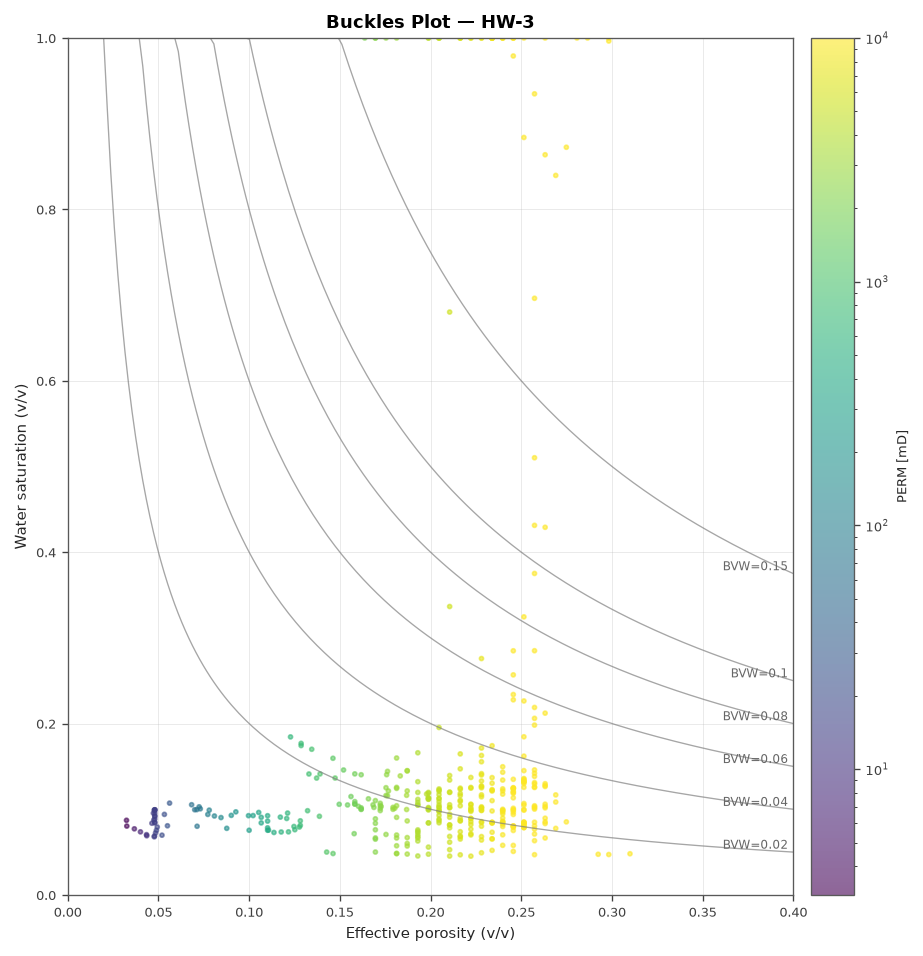

In [14]:
fig = create_buckles_plot(carb, phie_curve="PHIE", sw_curve="SW", color_curve="PERM")
plt.show()

## 4. Specialist panels

### 4a. Flow-unit (RQI vs phi_z) plot

`create_flow_unit_plot` renders a Reservoir Quality Index / flow-zone-indicator analysis.
Compute the units with `calculate_flow_units(perm_k, phi_e)` (note: **permeability
first**), then hand the result straight to the plot. The analysis only separates units
when permeability genuinely varies at fixed porosity, so we feed it **real core plugs**:
30/6-5 carries `PHIC` (core porosity) and `KH_CORE` (core horizontal permeability). A
log-derived `PERM` curve would be a poor input here - the dynamic workflow computes it
*from* porosity, so its FZI collapses onto a single trend by construction. On the
log-log RQI-vs-phi_z axes each unit clusters around its own constant-FZI line, so the
units stack as parallel diagonal bands.

core plugs with both PHIC and KH_CORE: 198
flow-unit result type: FlowUnitResult | units found: 6


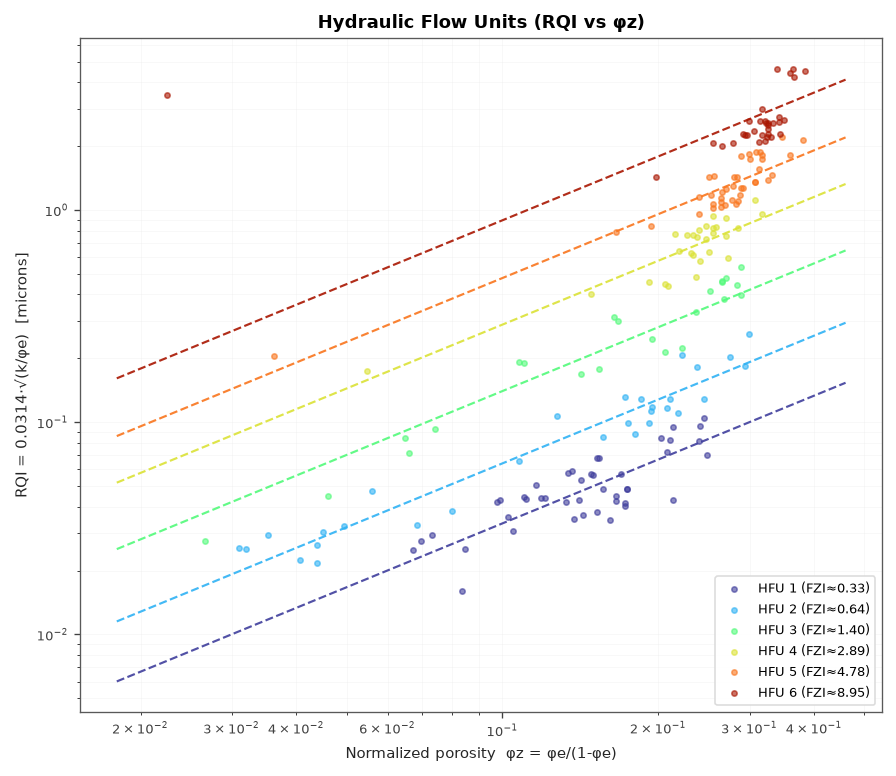

In [15]:
# Real core plugs on 30/6-5: PHIC = core porosity, KH_CORE = core horizontal perm.
phic = geo.get("PHIC").data
kh_core = geo.get("KH_CORE").data
plugs = np.isfinite(phic) & np.isfinite(kh_core)
print("core plugs with both PHIC and KH_CORE:", int(plugs.sum()))

fu = calculate_flow_units(kh_core[plugs], phic[plugs])   # perm_k first, then phi_e
print("flow-unit result type:", type(fu).__name__, "| units found:", fu.n_units)

create_flow_unit_plot(result=fu)
plt.show()

### 4b. NMR panel - real CMR (Daydream 1)

`create_nmr_panel` builds the standard CMR display: GR with cable tension (CDF, TENS), borehole calipers,
CMR porosity split into bound and free fluid, NMR permeability, and Swirr with
the T2 cutoff (a single cutoff is stated in the track title). It needs NMR summary curves such as `TCMR`, `CMFF`, `KTIM`;
`has_nmr_curves(well)` tells you whether a well qualifies.

Neither teaching well carries NMR, but the package bundles the **real
Daydream 1 CMR log** (lesson 14 works it end to end), and its curves are
exactly what the panel wants. The window below covers the coal streaks around
3900-4100 m.

has_nmr_curves -> True


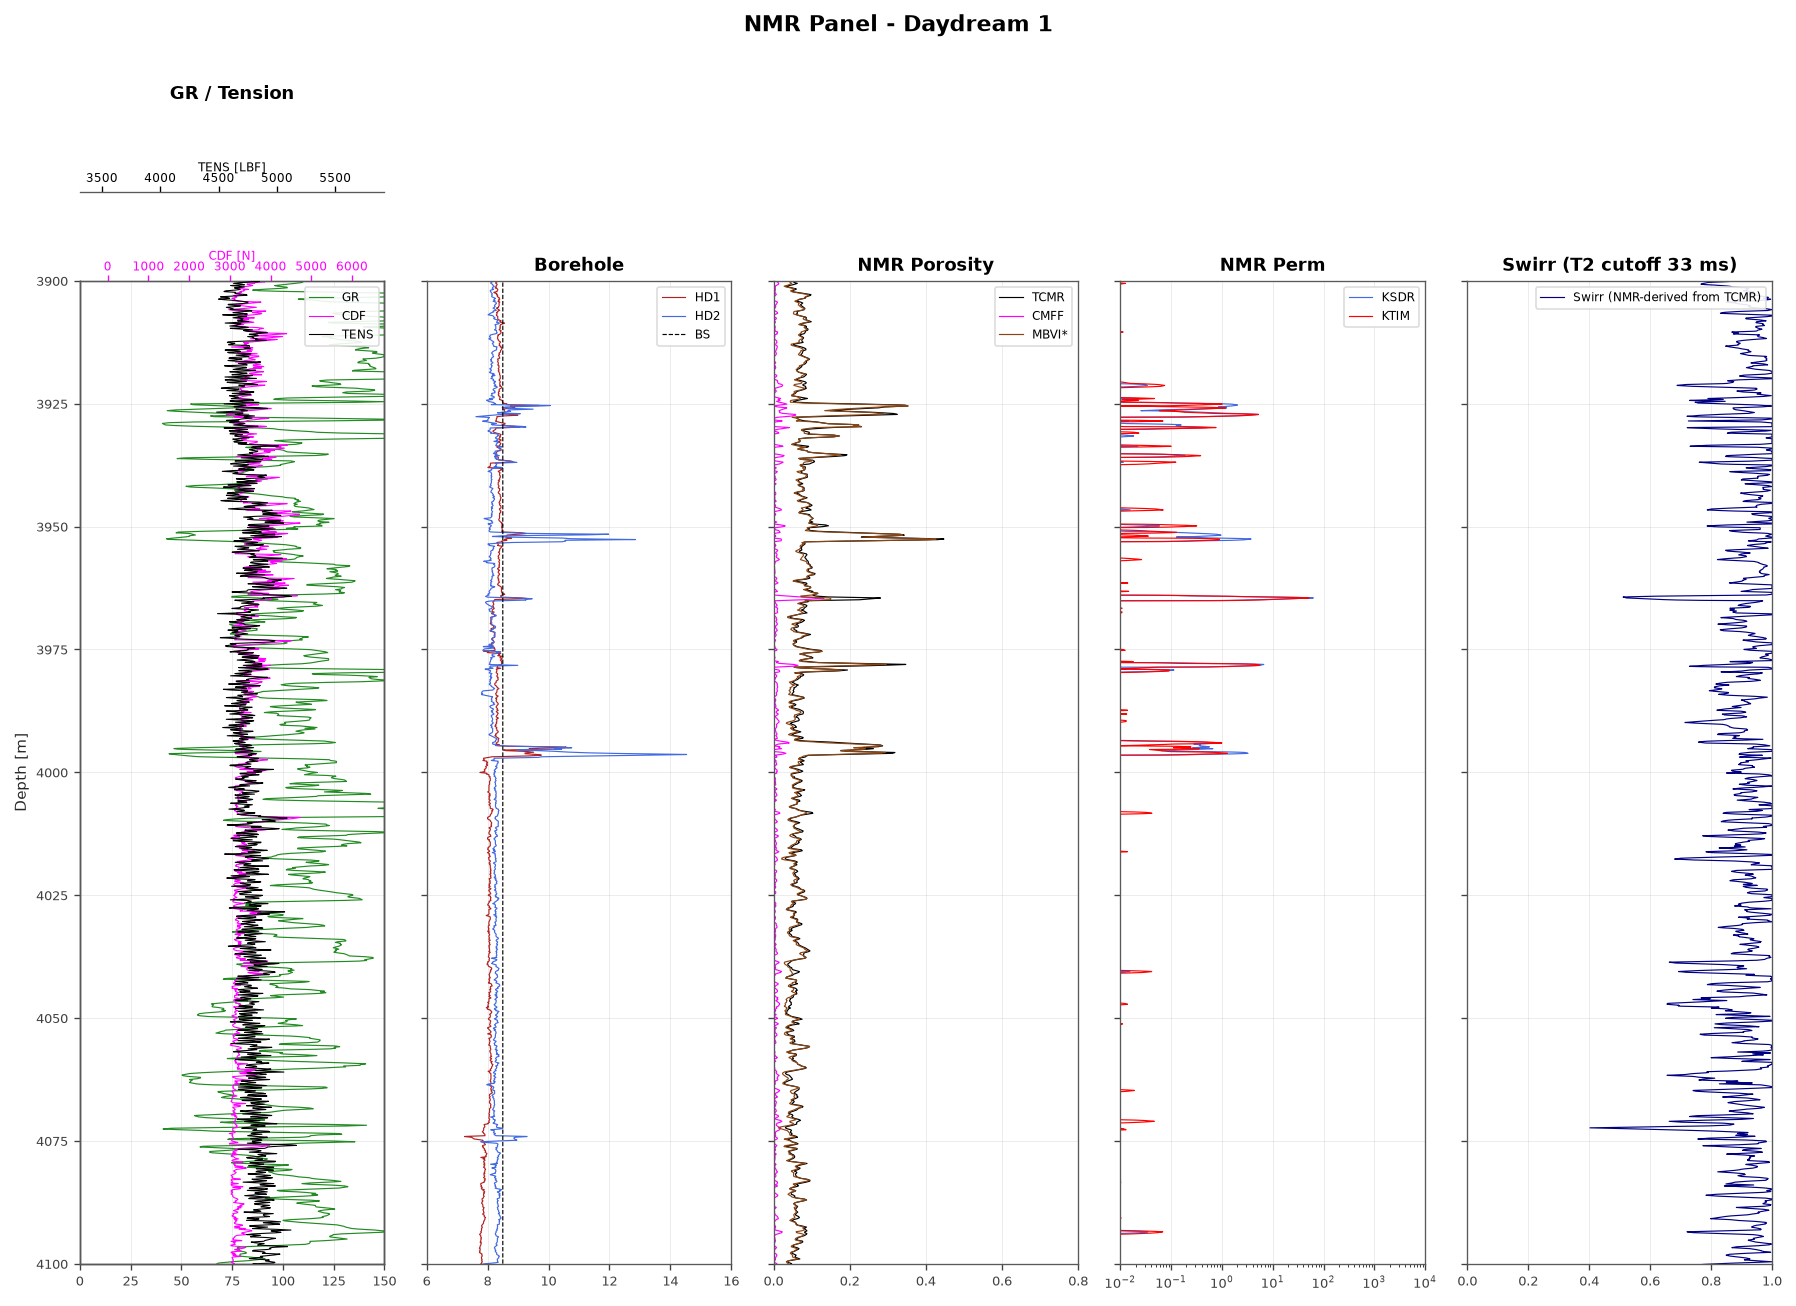

In [16]:
nmr_well = read_las(petrophys.sample("daydream1_cmr"))
print("has_nmr_curves ->", has_nmr_curves(nmr_well))

create_nmr_panel(nmr_well, depth_range=(3900.0, 4100.0))
plt.show()

### 4c. FMI panel - rendered in lesson 16

`create_fmi_panel` takes a `BoreholeImageData` (a pad/button resistivity image
plus a navigation curve), orients it to azimuth, equalizes, and renders the
standard image display. The large Daydream image DLIS is held in Git LFS rather
than the Python wheel, so the panel is not rendered here. Lesson 16 renders it; it
needs the `[dlis]` extra and the image file (`git lfs pull` in a repository clone,
or the `PETROPHYS_FMI_DLIS` environment variable pointing at the file).

## 5. Zone flags and formation shading

`plot_zone_flags` renders discrete flag curves (net rock / reservoir / pay) as coloured
bars against depth - an at-a-glance summary of where the pay is. It returns
`(fig, axes)`.

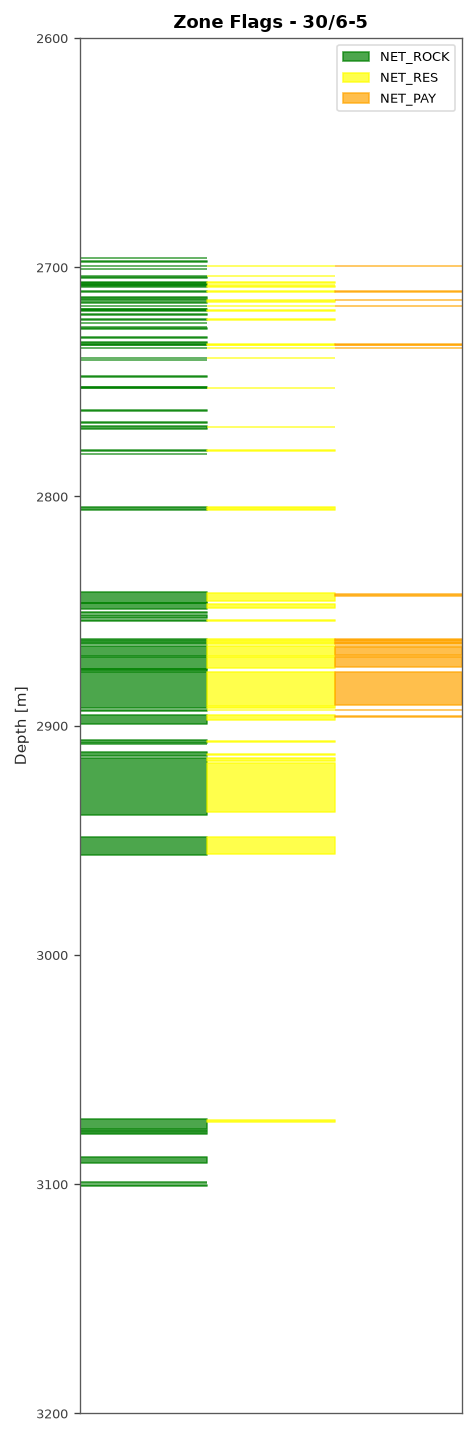

In [17]:
fig, ax = plot_zone_flags(
    geo, flag_curves=["NET_ROCK", "NET_RES", "NET_PAY"], depth_range=GEO_FULL,
)
plt.show()

`add_zone_shading` decorates an existing axis with translucent depth bands - handy for
highlighting named intervals on any custom track. Each zone is a dict with `top` and
`bottom` plus optional `name` and `color` keys; the zone `name` is drawn on the band
and used in the legend.

The bands below are the Brent (`BAAT GP.`, its NPD name), Dunlin and Statfjord intervals of the
bundled 30/6-5 formation tops.

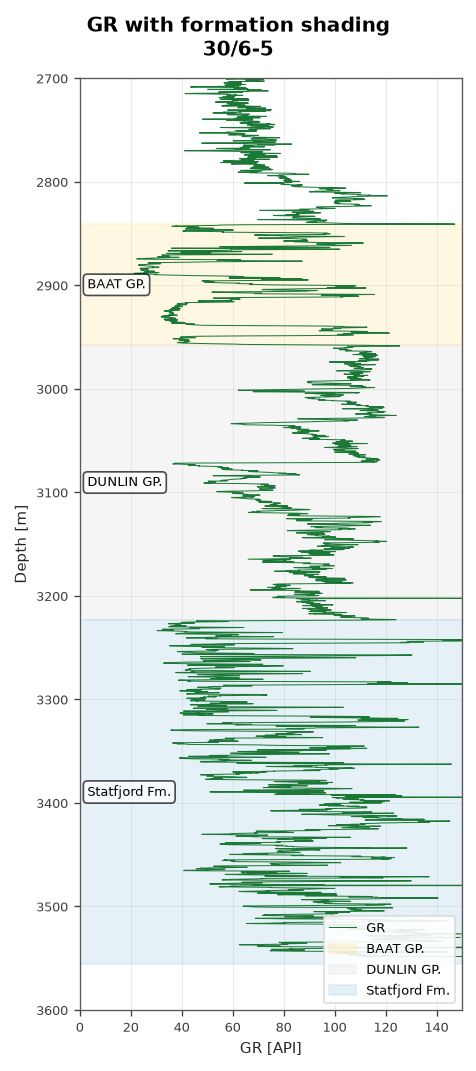

In [18]:
from petrophys.visualization import LogPlot

# Render GR with the library LogPlot, then decorate its axis with formation
# shading. add_zone_shading operates on any matplotlib axis, including the one
# LogPlot creates.
lp = LogPlot(geo, figsize=(4, 9))
lp.create_figure(n_tracks=1)
lp.add_curve(0, "GR", color="#1b7837", linewidth=0.6, xlim=(0, 150))
lp.set_depth_range(top=2700.0, bottom=3600.0)   # wide enough to hold both zones
lp.add_title("GR with formation shading")

import pandas as pd

tops = pd.read_csv(pp.sample("formations_30_6-5"))
colors = {"BAAT GP.": "#fee08b", "DUNLIN GP.": "#d9d9d9", "Statfjord Fm.": "#9ecae1"}
zones = [
    {"top": row.top_depth, "bottom": row.bottom_depth, "name": row.formation_name, "color": colors[row.formation_name]}
    for row in tops.itertuples() if row.formation_name in colors
]
add_zone_shading(lp.axes[0], zones, alpha=0.25)
lp.axes[0].legend(loc="lower right", fontsize=8)
lp.show()

## 6. Non-log analytics helpers

Beyond depth-track logs and crossplots, `petrophys.visualization` ships a small
set of **general analytics charts** for multi-well studies, model comparisons
and sensitivity work. They take plain arrays (or `Well` objects) so you never
hand-roll matplotlib:

- `create_multiwell_overlay` - one curve versus depth across several wells;
- `create_bar_comparison` - single or grouped ranking bars;
- `create_tornado_plot` - a sensitivity tornado about a base case;
- `create_histogram_comparison` - overlaid distributions;
- `create_line_comparison` - generic x versus many y-series lines.

We demonstrate each on real Geolink wells.

### 6a. Multi-well curve overlay

`create_multiwell_overlay(wells, curve, ...)` overlays one curve versus depth for
several wells on a shared axis - a quick cross-well QC view. At one depth different wells cut
different stratigraphy, so for GR normalization compare distributions (6d) rather than traces. With
`normalize=True` each curve is robustly min-max scaled to 0-1 so their shapes
compare directly regardless of absolute GR level.

wells with GR: ['30/6-5', '16/7-1', '25/5-1 Froey', '15/9-14']


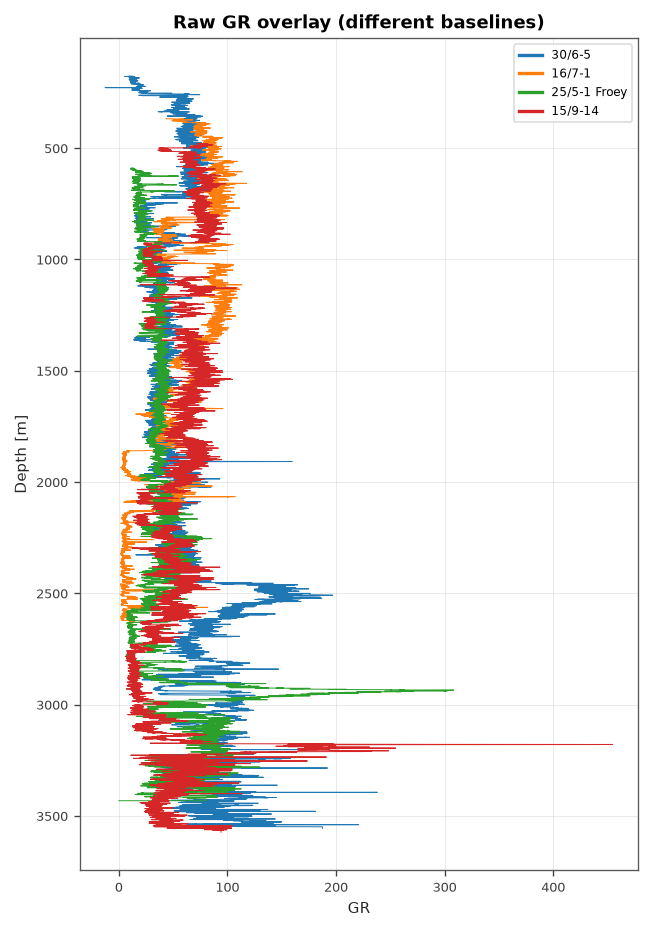

In [19]:
from petrophys.visualization import (
    create_multiwell_overlay, create_bar_comparison, create_tornado_plot,
    create_histogram_comparison, create_line_comparison,
)

# Load a few Geolink wells (all in metres) that carry GR.
field_names = ["30_6-5", "16_7-1", "25_5-1", "15_9-14"]
field_wells = [read_las(petrophys.sample(n)) for n in field_names]
field_wells = [w for w in field_wells if w.has_curve("GR")]
print("wells with GR:", [w.name for w in field_wells])

fig, ax = create_multiwell_overlay(
    field_wells, "GR", normalize=False,
    title="Raw GR overlay (different baselines)", figsize=(6, 9),
)
plt.show()

### 6b. Grouped bar comparison

`create_bar_comparison(categories, values, ...)` draws single or grouped bars.
`values` may be a 1-D sequence or a `{series: values}` mapping for grouped bars;
`sort_by` ranks the categories by a chosen series. Here it shows the zone summary of
the 30/6-5 interpretation - net rock, net reservoir and net pay per formation from
`formation_summary` - kept in stratigraphic order (no `sort_by`).

    Formation  Gross (m)  Net Rock (m)  Net Reservoir (m)  Net Pay (m)
  Heather Fm.      248.0          13.0                5.5          1.7
     Ness Fm.       24.1          11.1                7.6          2.1
    Etive Fm.       93.0          65.4               58.5         23.3
    Drake Fm.      113.1           0.0                0.0          0.0
     Cook Fm.       52.0           9.6                1.2          0.0
 Amundsen Fm.      100.0           0.0                0.0          0.0
Statfjord Fm.      333.0         185.8               48.2          0.9


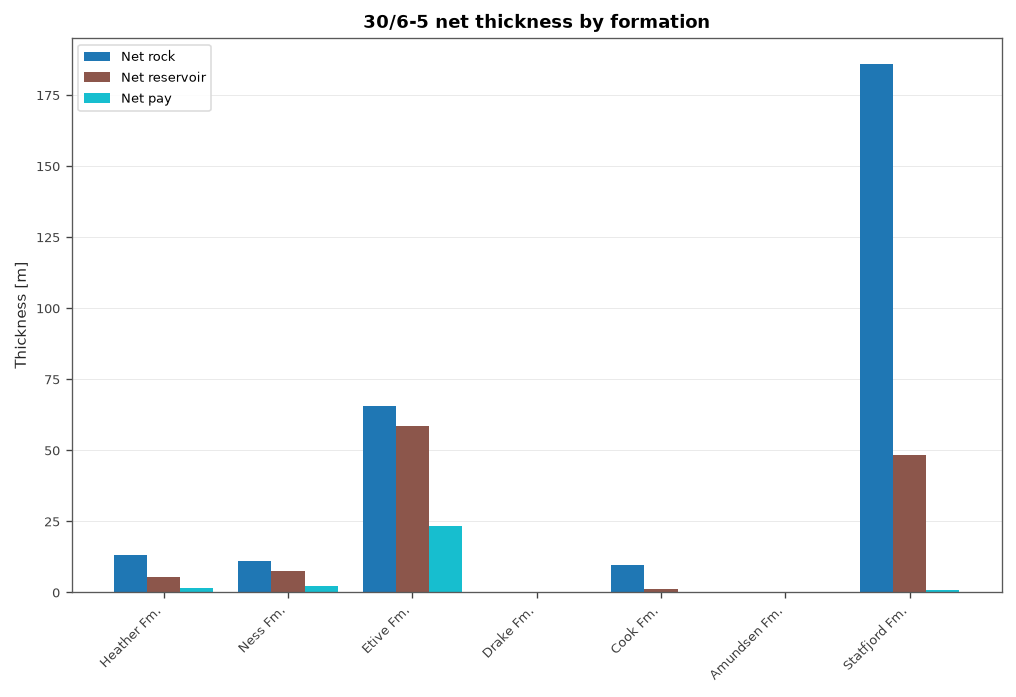

In [20]:
fsum = geo_result.formation_summary(pp.sample("formations_30_6-5"), rank="formation")
fsum = fsum[fsum["Top"] >= 2593.0]          # Heather Fm. down to Statfjord Fm.
print(fsum[["Formation", "Gross (m)", "Net Rock (m)", "Net Reservoir (m)", "Net Pay (m)"]].round(1).to_string(index=False))

fig, ax = create_bar_comparison(
    list(fsum["Formation"]),
    {"Net rock": list(fsum["Net Rock (m)"]), "Net reservoir": list(fsum["Net Reservoir (m)"]),
     "Net pay": list(fsum["Net Pay (m)"])},
    ylabel="Thickness [m]", title="30/6-5 net thickness by formation",
)
plt.show()

### 6c. Sensitivity tornado

`create_tornado_plot(labels, low, high, base, ...)` shows how an outcome swings
when each input takes its low/high setting, sorted widest-span-on-top. Below we
sweep an Archie water-saturation calculation (single representative point) over
+/- ranges of `Rw`, `m`, `n` and `PHIE`, and plot the resulting Sw span.

base Sw = 0.265


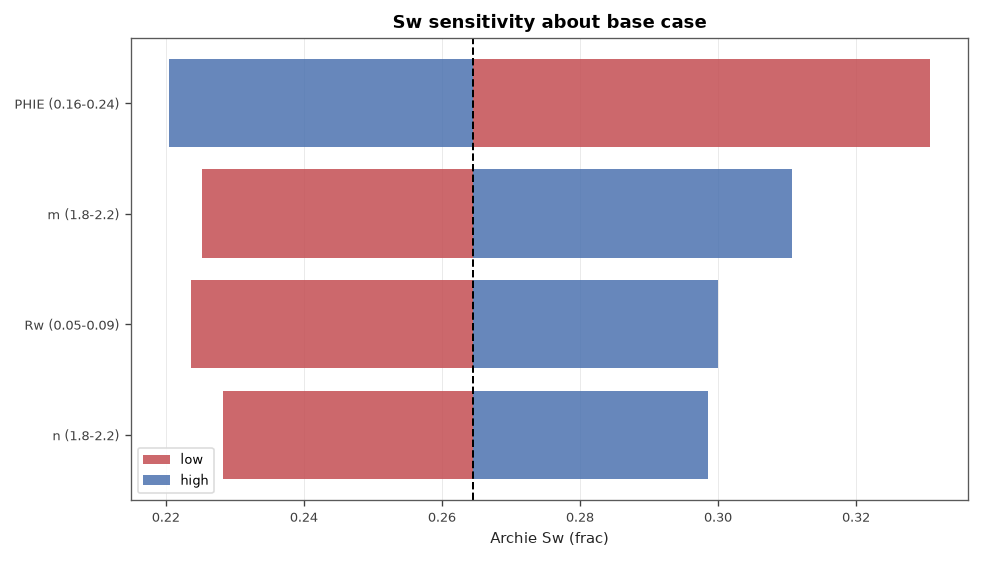

In [21]:
from petrophys.interpretation.saturation import archie

# Representative reservoir point on 30/6-5.
base = dict(rt=20.0, phie=0.20, rw=0.070, a=0.80, m=2.0, n=2.0)   # operator constants (lesson 09)
def sw(**kw):
    p = dict(base); p.update(kw)
    return float(archie(rt=p["rt"], rw=p["rw"], phi=p["phie"],
                        a=p["a"], m=p["m"], n=p["n"]))

sw_base = sw()
params = {
    "Rw (0.05-0.09)":  (sw(rw=0.05), sw(rw=0.09)),
    "m (1.8-2.2)":     (sw(m=1.8),   sw(m=2.2)),
    "n (1.8-2.2)":     (sw(n=1.8),   sw(n=2.2)),
    "PHIE (0.16-0.24)":(sw(phie=0.16), sw(phie=0.24)),
}
labels = list(params)
low = [params[k][0] for k in labels]
high = [params[k][1] for k in labels]
print("base Sw = %.3f" % sw_base)

fig, ax = create_tornado_plot(
    labels, low, high, base=sw_base,
    xlabel="Archie Sw (frac)", title="Sw sensitivity about base case",
)
plt.show()

### 6d. Histogram comparison

`create_histogram_comparison({label: array, ...})` overlays distributions on a
common bin grid. A classic use is comparing a curve's spread across wells (or
before/after normalization); here we compare each well's GR distribution. `histtype="step"` keeps several wells
readable and `value_range` keeps a few spikes from stretching the bins.

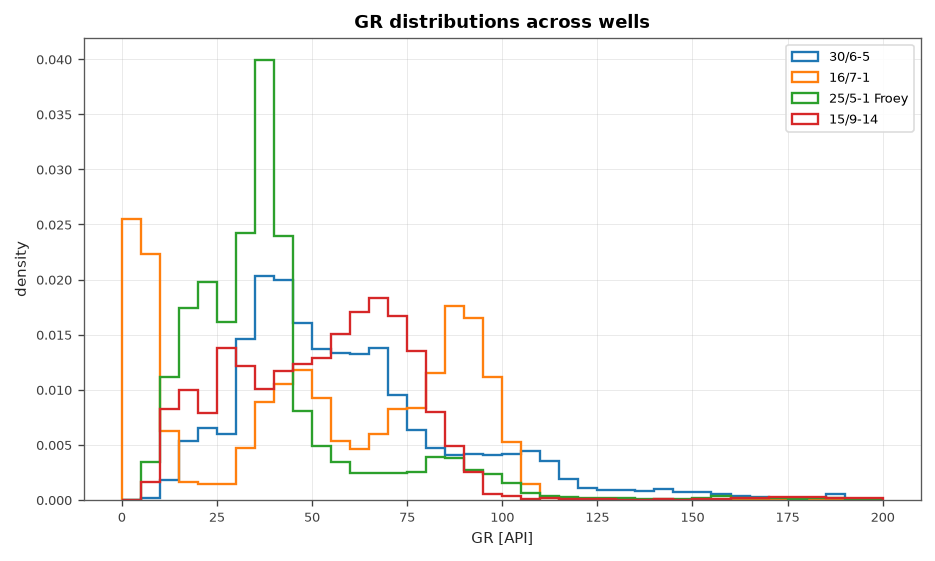

In [22]:
gr_dists = {w.name: w.get("GR").data for w in field_wells}
fig, ax = create_histogram_comparison(
    gr_dists, bins=40, density=True, value_range=(0, 200), histtype="step",
    xlabel="GR [API]", title="GR distributions across wells",
)
plt.show()

### 6e. Line comparison (transfer functions)

`create_line_comparison(x, {label: y, ...})` is the generic x-versus-many-series
plotter for things that are not depth tracks: transfer functions, temperature
profiles, and similar. Here we compare the common **Vcl-from-GR transfer
functions** (linear vs the two Larionov forms and Clavier) over the full IGR
range.

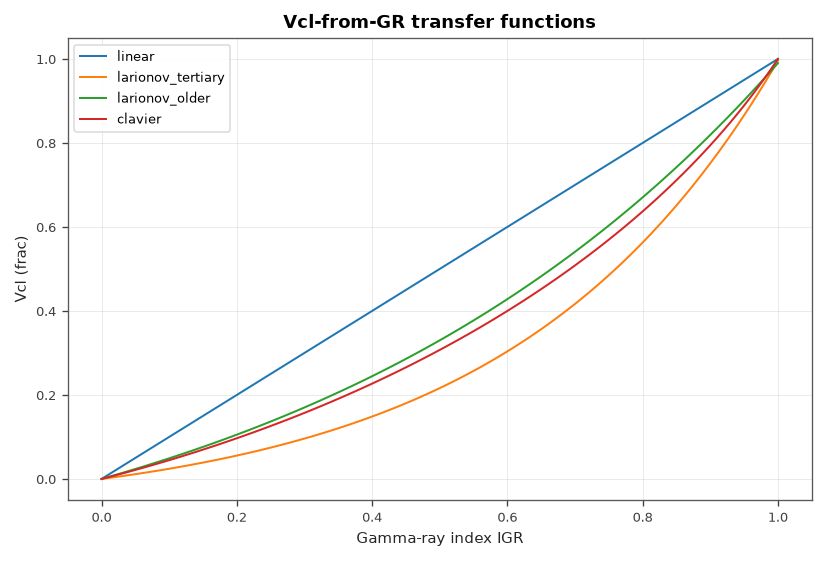

In [23]:
from petrophys.interpretation.clay_volume import vcl_from_gr

igr = np.linspace(0.0, 1.0, 101)     # gamma-ray index (0 clean -> 1 shale)
gr = igr * 100.0                     # map onto a 0-100 API scale (gr_min=0, gr_max=100)
transfer = {
    "linear":            vcl_from_gr(gr, 0.0, 100.0, method="linear"),
    "larionov_tertiary": vcl_from_gr(gr, 0.0, 100.0, method="larionov_tertiary"),
    "larionov_older":    vcl_from_gr(gr, 0.0, 100.0, method="larionov_older"),
    "clavier":           vcl_from_gr(gr, 0.0, 100.0, method="clavier"),
}
fig, ax = create_line_comparison(
    igr, transfer,
    xlabel="Gamma-ray index IGR", ylabel="Vcl (frac)",
    title="Vcl-from-GR transfer functions",
)
plt.show()

## Pitfalls & parameter choices

- **`create_log_viewer` renders immediately.** The factory builds the figure before it
  returns, so the `LogViewer` already holds `viewer.fig` / `viewer.axes` windowed to the
  `depth_range` you passed. Calling `.create()` again re-renders from scratch and
  **drops the depth window** unless you pass it again - a silent way to lose your zoom.
  Display the eagerly-built figure once; use `.close()` to free memory in loops.
- **`auto` template is curve-driven.** It excludes unavailable curve families.
  Inspect the adaptive template and `viewer.diagnostics["omitted_tracks"]` to distinguish
  absent curves from tracks with no finite samples in the selected window, and
  `viewer.diagnostics["optional_tracks"]` for tracks left out unless named in `tracks=`.
- **Pickett/Hingle need water points.** Run them on a **water-bearing** interval; a pure
  hydrocarbon zone has too few 100%-water points and the water-line fit degrades.
- **`calculate_flow_units(perm_k, phi_e)` takes permeability first.** Swapping the
  arguments silently produces nonsense bands. Feed it data where permeability truly
  varies at fixed porosity (core plugs such as `PHIC`/`KH_CORE`); a porosity-derived
  log `PERM` collapses FZI onto one trend.
- **Lithology crossplots need the right curves, and the curves must be right.** On
  30/6-5 the full lithology suite is recorded only in ~2784-3176 m, and even there
  `PEF` reads about 4.4 b/e in clean quartz sand, so PEF-based mineral volumes call
  the sandstones calcite. Check PEF against a known clean sand before using it.
- **Check default permeability against core.** On HW-3 the default carbonate
  permeability has a median in the thousands of mD, about three orders of
  magnitude above the file's `PERM_CC`.
- **NMR / FMI panels need the right inputs** (`has_nmr_curves`, a navigation curve).
  The NMR panel renders here from the bundled real Daydream 1 CMR; the FMI panel
  needs an image DLIS - lesson 16 runs it on the real Daydream 1 image.

## Recap

- The **template log viewer** (named or `auto`) is your general-purpose multi-track
  display; the **triple combo** is the fast first look.
- The **crossplot family** each answers a specific question: N-D for lithology/gas,
  Pickett/Hingle for `Rw`/`m` and the water line, M-N/MID for matrix mineralogy, Buckles
  for irreducible-water/producibility.
- **Specialist panels** cover flow units (real 30/6-5 core plugs) and the NMR
  display (real Daydream 1 CMR); the FMI panel renders in lesson 16.
- **Zone flags** and **formation shading** annotate results directly on depth.

## Try it yourself

> **Exercise 1.** Render `create_log_viewer(geo, template_defaults="petrophysics")` and
> compare its track layout with `geolink_full`. Which curves each template emphasises tells
> you its intended audience.
>
> **Exercise 2.** Re-run the Pickett plot with `m=1.8` and `m=2.2`. How does the assumed
> cementation exponent move the water line, and hence computed `Sw`?
>
> **Exercise 3.** Build a Buckles plot on the clastic well `geo` over `GEO_FULL`. Do the
> points hug a single `PHIE*SW` hyperbola (irreducible) or scatter (transition zone)?

## What's next

Continue with **18_multiwell_field_study.ipynb**, where these single-well plots scale up:
we batch-process the 17-well Costa field, normalise logs across wells, and build a
cross-well comparison table and summary figure.